# CICIDS2017 — Multiclass Intrusion Detection: GAN Oversampling + Ensemble + SHAP
Pipeline (29 steps): load → quality → EDA → **multiclass target** → split/scale → feature selection → **Original vs multiclass SMOTE vs conditional WGAN-GP** baselines → tuning → ensembles → feature importance → **SHAP (global / class-wise / local)** → multiclass + per-class evaluation → save.

**Conventions used throughout**
- Target = attack category (14 slots from the workflow: `BENIGN, DDoS, DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Slowhttptest, PortScan, Bot, FTP-Patator, SSH-Patator, Web Attack, Infiltration, Heartbleed, Other Attack Classes`). The three CICIDS2017 web-attack labels are merged into **Web Attack**; any label not in the list falls into **Other Attack Classes** (empty for the standard `MachineLearningCVE` CSVs — the notebook handles that automatically).
- Every fitted object (scaler, feature selection, SMOTE, GAN) is learned from the **training split only**. Validation and test sets keep the natural class distribution and never contain synthetic rows.
- CICIDS2017 has ~2.5M rows, so the training split is capped **per class** (`CLASS_CAP`): big classes are down-sampled, rare classes (Heartbleed, Infiltration …) keep every row. All scenarios (Original / SMOTE / GAN) use the *same* real training rows.
- "Minority classes" = classes with fewer than `OVERSAMPLE_TARGET` training rows. SMOTE and the GAN both raise each of them to exactly that size, so the comparison is like-for-like.

## 01 · Import libraries

In [1]:
! pip install scikit-learn


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
    matthews_corrcoef,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap
import joblib

e:\BRM003-ML-Project\brmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
%%writefile ids_utils.py
# Helper module saved next to the notebook so that the saved model / scaler can be re-loaded anywhere.
import json
from pathlib import Path
import numpy as np
import pandas as pd
import joblib


def signed_log1p(X):
    """sign(x) * log1p(|x|): tames CICIDS2017's heavy tails while keeping negative values (e.g. Init_Win_bytes = -1)."""
    X = np.asarray(X)
    if X.dtype.kind != "f":
        X = X.astype("float32")
    return np.sign(X) * np.log1p(np.abs(X))


class PrefitSoftVoting:
    """Average predict_proba of already-fitted multiclass models; prediction = argmax of the mean probability."""
    def __init__(self, models, weights=None):
        self.models = list(models)
        self.weights = weights
        self.classes_ = np.asarray(self.models[0].classes_)

    def predict_proba(self, X):
        P = np.stack([m.predict_proba(X) for m in self.models], axis=0)
        return np.average(P, axis=0, weights=self.weights)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class PrefitHardVoting:
    """Majority vote of already-fitted multiclass models (ties broken by the mean probability).
    predict_proba = fraction of models voting for each class."""
    def __init__(self, models):
        self.models = list(models)
        self.classes_ = np.asarray(self.models[0].classes_)

    def _scores(self, X):
        n, k = len(X), len(self.classes_)
        votes, soft = np.zeros((n, k)), np.zeros((n, k))
        for m in self.models:
            P = m.predict_proba(X)
            votes[np.arange(n), P.argmax(axis=1)] += 1
            soft += P / len(self.models)
        return votes / len(self.models), soft

    def predict_proba(self, X):
        return self._scores(X)[0]

    def predict(self, X):
        votes, soft = self._scores(X)
        return self.classes_[(votes + 1e-3 * soft).argmax(axis=1)]


class IDSDetector:
    """Load the saved artefacts and score RAW CICIDS2017 flow rows (same columns as the CSVs)."""
    def __init__(self, model_dir="models"):
        d = Path(model_dir)
        self.model = joblib.load(d / "final_model.joblib")
        self.preprocessor = joblib.load(d / "preprocessor.joblib")
        self.label_encoder = joblib.load(d / "label_encoder.joblib")
        self.feature_columns = json.load(open(d / "feature_columns.json"))
        self.selected_features = json.load(open(d / "selected_features.json"))

    def _prep(self, raw_df):
        X = raw_df.copy()
        X.columns = X.columns.str.strip()
        X = X[self.feature_columns].replace([np.inf, -np.inf], np.nan).fillna(0)
        return self.preprocessor.transform(X)[self.selected_features].astype("float32")

    def predict_proba(self, raw_df):
        """(n_flows, n_classes) probabilities; column order = label_encoder.classes_."""
        return self.model.predict_proba(self._prep(raw_df))

    def predict(self, raw_df):
        """Attack-category names."""
        return self.label_encoder.inverse_transform(self.model.predict(self._prep(raw_df)))

Overwriting ids_utils.py


In [4]:
import os, gc, time, json, warnings, math
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from imblearn.over_sampling import SMOTE
from scipy.stats import ks_2samp
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import PredefinedSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

from ids_utils import signed_log1p, PrefitSoftVoting, PrefitHardVoting, IDSDetector

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")

In [5]:
# ---------------- CONFIG: the only cell you need to edit to trade speed for fidelity ----------------
RANDOM_STATE      = 42
CLASS_CAP         = 60_000   # max real training rows kept PER CLASS (None = keep everything). Rare classes keep all rows.
OVERSAMPLE_TARGET = 10_000   # every class with fewer training rows than this is oversampled up to it (SMOTE and GAN)
BASE_TREES        = 100      # trees for the un-tuned Random Forest
BOOST_ROUNDS      = 150      # boosting rounds for the un-tuned XGBoost / LightGBM (multiclass grows 1 tree per class per round)
CORR_THRESHOLD    = 0.95     # drop one feature of every pair with |r| above this
IMPORTANCE_CUM    = 0.95     # keep features that make up this share of RF importance
FS_PER_CLASS      = 20_000   # rows per class used for the feature-selection Random Forest
GAN_ITERS         = 6000     # generator updates (each = 5 critic updates)
GAN_BATCH         = 256
GAN_LATENT        = 64
TUNE_PER_CLASS    = 8_000    # rows per class of the GAN-balanced train used inside the tuning search
TUNE_VAL_PER_CLASS= 5_000    # real validation rows per class used to score each tuning trial
TUNE_ITER         = 8        # random-search trials per model
SHAP_PER_CLASS    = 100      # test rows per class explained with SHAP
SHAP_PER_CLASS_RF = 20       # Random Forest SHAP is slow -> fewer rows per class
MODEL_DIR = Path("models"); FIG_DIR = Path("figures"); OUT_DIR = Path("outputs")
for d in (MODEL_DIR, FIG_DIR, OUT_DIR): d.mkdir(exist_ok=True)

np.random.seed(RANDOM_STATE); torch.manual_seed(RANDOM_STATE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def show(name=None):
    plt.tight_layout()
    if name: plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def cap_per_class(y, cap, seed=RANDOM_STATE):
    """Row positions keeping at most `cap` rows of every class (all rows of smaller classes)."""
    y = np.asarray(y); rng = np.random.default_rng(seed); keep = []
    for k in np.unique(y):
        ix = np.flatnonzero(y == k)
        if cap and len(ix) > cap: ix = rng.choice(ix, cap, replace=False)
        keep.append(ix)
    return np.sort(np.concatenate(keep))

device: cpu


## 02 · Load CICIDS2017 (all 8 CSVs)
The raw `Label` column is kept as text; the multiclass target is built from it in step 07.

In [6]:
data_dir = Path(r"E:\BRM003-ML-Project\dataset folder\archive (2)\MachineLearningCVE")
csv_files = sorted(data_dir.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CICIDS2017 CSV files found in {data_dir}")

data_df = pd.concat(
    (pd.read_csv(csv_file, skipinitialspace=True) for csv_file in csv_files),
    ignore_index=True,
)
data_df.columns = data_df.columns.str.strip()

if "Label" not in data_df.columns:
    raise ValueError("The CICIDS2017 CSV files must contain a 'Label' column")

# non-ASCII dash in 'Web Attack – ...' replaced so names are clean
data_df["Label"] = data_df["Label"].astype(str).str.strip().str.replace(r"[^\x00-\x7F]+", "-", regex=True)

print(f"Loaded {len(csv_files)} CSV files; dataset shape: {data_df.shape}")
display(data_df["Label"].value_counts().to_frame("raw_count"))
display(data_df.head())

Loaded 8 CSV files; dataset shape: (2830743, 79)


,raw_count
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"110,091.7431","18,348.6238",109.0000,0.0000,109,109,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"9,174.3119","9,174.3119",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"230,769.2308","38,461.5385",52.0000,0.0000,52,52,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"19,230.7692","19,230.7692",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"352,941.1765","58,823.5294",34.0000,0.0000,34,34,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"29,411.7647","29,411.7647",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN


## 03 · Verify dataset structure

In [7]:
FEATURE_COLS_RAW = [c for c in data_df.columns if c != "Label"]
print("Files loaded      :", [f.name for f in csv_files])
print("Rows x columns    :", data_df.shape)
print("Feature columns   :", len(FEATURE_COLS_RAW))
print("Has Label         :", "Label" in data_df)
print("Distinct raw labels:", data_df["Label"].nunique())
assert len(FEATURE_COLS_RAW) >= 70, "Unexpected number of feature columns - check the CSV files"

Files loaded      : ['Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv']
Rows x columns    : (2830743, 79)
Feature columns   : 78
Has Label         : True
Distinct raw labels: 15


## 04 · Dataset overview

In [8]:
print("shape:", data_df.shape)
display(data_df.head())
data_df.info()

shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"110,091.7431","18,348.6238",109.0000,0.0000,109,109,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"9,174.3119","9,174.3119",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"230,769.2308","38,461.5385",52.0000,0.0000,52,52,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"19,230.7692","19,230.7692",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0000,0.0000,6,6,6.0000,0.0000,"352,941.1765","58,823.5294",34.0000,0.0000,34,34,0,0.0000,0.0000,0,0,0,0.0000,0.0000,0,0,0,0,0,0,20,20,"29,411.7647","29,411.7647",6,6,6.0000,0.0000,0.0000,0,0,0,0,1,1,0,0,1,9.0000,6.0000,6.0000,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0000,0.0000,0,0,0.0000,0.0000,"4,000,000.0000","666,666.6667",3.0000,0.0000,3,3,3,3.0000,0.0000,3,3,0,0.0000,0.0000,0,0,0,0,0,0,40,0,"666,666.6667",0.0000,6,6,6.0000,0.0000,0.0000,0,0,0,0,1,0,0,0,0,9.0000,6.0000,0.0000,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN


<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 int64  
 19  Flow IAT Mi

In [9]:
display(data_df.describe().T)
print(data_df.dtypes.value_counts())

e:\BRM003-ML-Project\brmenv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
e:\BRM003-ML-Project\brmenv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
Destination Port,"2,830,743.0000","8,071.4825","18,283.6322",0.0000,53.0000,80.0000,443.0000,"65,535.0000"
Flow Duration,"2,830,743.0000","14,785,663.9295","33,653,744.0859",-13.0000,155.0000,"31,316.0000","3,204,828.5000","119,999,998.0000"
Total Fwd Packets,"2,830,743.0000",9.3612,749.6728,1.0000,2.0000,2.0000,5.0000,"219,759.0000"
Total Backward Packets,"2,830,743.0000",10.3938,997.3883,0.0000,1.0000,2.0000,4.0000,"291,922.0000"
Total Length of Fwd Packets,"2,830,743.0000",549.3024,"9,993.5892",0.0000,12.0000,62.0000,187.0000,"12,900,000.0000"
...,...,...,...,...,...,...,...,...
Active Min,"2,830,743.0000","58,295.8177","577,092.2819",0.0000,0.0000,0.0000,0.0000,"110,000,000.0000"
Idle Mean,"2,830,743.0000","8,316,036.6272","23,630,078.5780",0.0000,0.0000,0.0000,0.0000,"120,000,000.0000"
Idle Std,"2,830,743.0000","503,843.9498","4,602,984.4807",0.0000,0.0000,0.0000,0.0000,"76,900,000.0000"
Idle Max,"2,830,743.0000","8,695,751.9846","24,366,888.3290",0.0000,0.0000,0.0000,0.0000,"120,000,000.0000"


int64      54
float64    24
str         1
Name: count, dtype: int64


## 05 · Data quality
Inspect first, then clean. Cleaning is row-wise/deterministic (no statistics learned), so doing it before the split does not leak information — and **removing duplicates before splitting prevents identical flows from landing in both train and test**. The table after cleaning shows how many rows each raw attack label lost: that matters for the rare classes.

In [10]:
feat = FEATURE_COLS_RAW
num = data_df[feat]

missing = num.isna().sum();                 missing = missing[missing > 0]
inf_counts = np.isinf(num).sum();           inf_counts = inf_counts[inf_counts > 0]
neg_counts = (num < 0).sum();               neg_counts = neg_counts[neg_counts > 0]
const_cols = [c for c in feat if num[c].nunique(dropna=True) <= 1]
n_dup = int(data_df.duplicated().sum())

print("Missing values per column :\n", missing if len(missing) else "none")
print("\nInfinite values per column:\n", inf_counts if len(inf_counts) else "none")
print(f"\nDuplicate rows            : {n_dup:,} ({n_dup/len(data_df):.2%})")
print("\nZero-variance columns     :", const_cols or "none")
print("\nColumns with negative values (some are legitimate, e.g. Init_Win_bytes = -1):\n", neg_counts if len(neg_counts) else "none")

Missing values per column :
 Flow Bytes/s    1358
dtype: int64

Infinite values per column:
 Flow Bytes/s      1509
Flow Packets/s    2867
dtype: int64

Duplicate rows            : 308,381 (10.89%)

Zero-variance columns     : ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Columns with negative values (some are legitimate, e.g. Init_Win_bytes = -1):
 Flow Duration                  115
Flow Bytes/s                    85
Flow Packets/s                 115
Flow IAT Mean                  115
Flow IAT Max                   115
Flow IAT Min                  2891
Fwd IAT Min                     17
Fwd Header Length               35
Bwd Header Length               22
Fwd Header Length.1             35
Init_Win_bytes_forward     1001189
Init_Win_bytes_backward    1441552
min_seg_size_forward            35
dtype: int64


In [11]:
# ---- cleaning ----
n0 = len(data_df); raw_label_counts = data_df["Label"].value_counts()
clean_df = data_df.replace([np.inf, -np.inf], np.nan)
clean_df = clean_df.dropna(subset=feat);                              n1 = len(clean_df)   # NaN / inf rows
must_be_nonneg = [c for c in ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                              "Flow Bytes/s", "Flow Packets/s"] if c in feat]
clean_df = clean_df[(clean_df[must_be_nonneg] >= 0).all(axis=1)];       n2 = len(clean_df)   # physically invalid
clean_df = clean_df.drop_duplicates();                                   n3 = len(clean_df)   # duplicates
FEATURE_COLS = [c for c in feat if c not in const_cols]
clean_df = clean_df[FEATURE_COLS + ["Label"]].reset_index(drop=True)
clean_df[FEATURE_COLS] = clean_df[FEATURE_COLS].astype("float32")

print(f"start {n0:,} -> NaN/inf removed {n0-n1:,} -> invalid removed {n1-n2:,} -> duplicates removed {n2-n3:,} -> final {n3:,}")
print(f"features kept: {len(FEATURE_COLS)} (dropped constant: {const_cols})")
display(pd.DataFrame({"raw": raw_label_counts, "after_cleaning": clean_df["Label"].value_counts()}).fillna(0).astype(int)
        .assign(kept_pct=lambda d: (d.after_cleaning / d.raw * 100).round(1)))
del data_df, num; gc.collect()

start 2,830,743 -> NaN/inf removed 2,867 -> invalid removed 115 -> duplicates removed 307,070 -> final 2,520,691
features kept: 70 (dropped constant: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'])


,raw,after_cleaning,kept_pct
Label,,,
BENIGN,2273097,2094950,92.2000
Bot,1966,1948,99.1000
DDoS,128027,128014,100.0000
DoS GoldenEye,10293,10286,99.9000
DoS Hulk,231073,172846,74.8000
DoS Slowhttptest,5499,5228,95.1000
DoS slowloris,5796,5385,92.9000
FTP-Patator,7938,5931,74.7000
Heartbleed,11,11,100.0000


20

## 06 · Exploratory data analysis

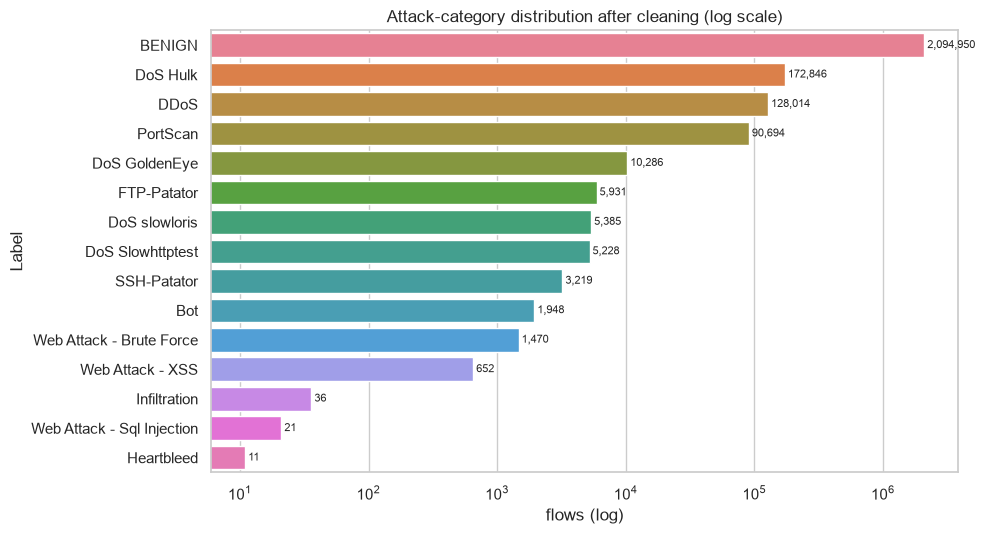

BENIGN share: 83.1% | rarest class: Heartbleed (11 flows)


In [12]:
# Attack category distribution (raw CICIDS2017 labels, before grouping in step 07)
lab_counts = clean_df["Label"].value_counts()
plt.figure(figsize=(10, 5.5))
ax = sns.barplot(x=lab_counts.values, y=lab_counts.index, hue=lab_counts.index, legend=False); ax.set_xscale("log")
for i, v in enumerate(lab_counts.values): ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.title("Attack-category distribution after cleaning (log scale)"); plt.xlabel("flows (log)")
show("eda_attack_categories")
print(f"BENIGN share: {lab_counts.get('BENIGN', 0) / lab_counts.sum():.1%} | rarest class: {lab_counts.idxmin()} ({lab_counts.min():,} flows)")

Categorical feature columns: none (CICIDS2017 flow features are all numeric)


e:\BRM003-ML-Project\brmenv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


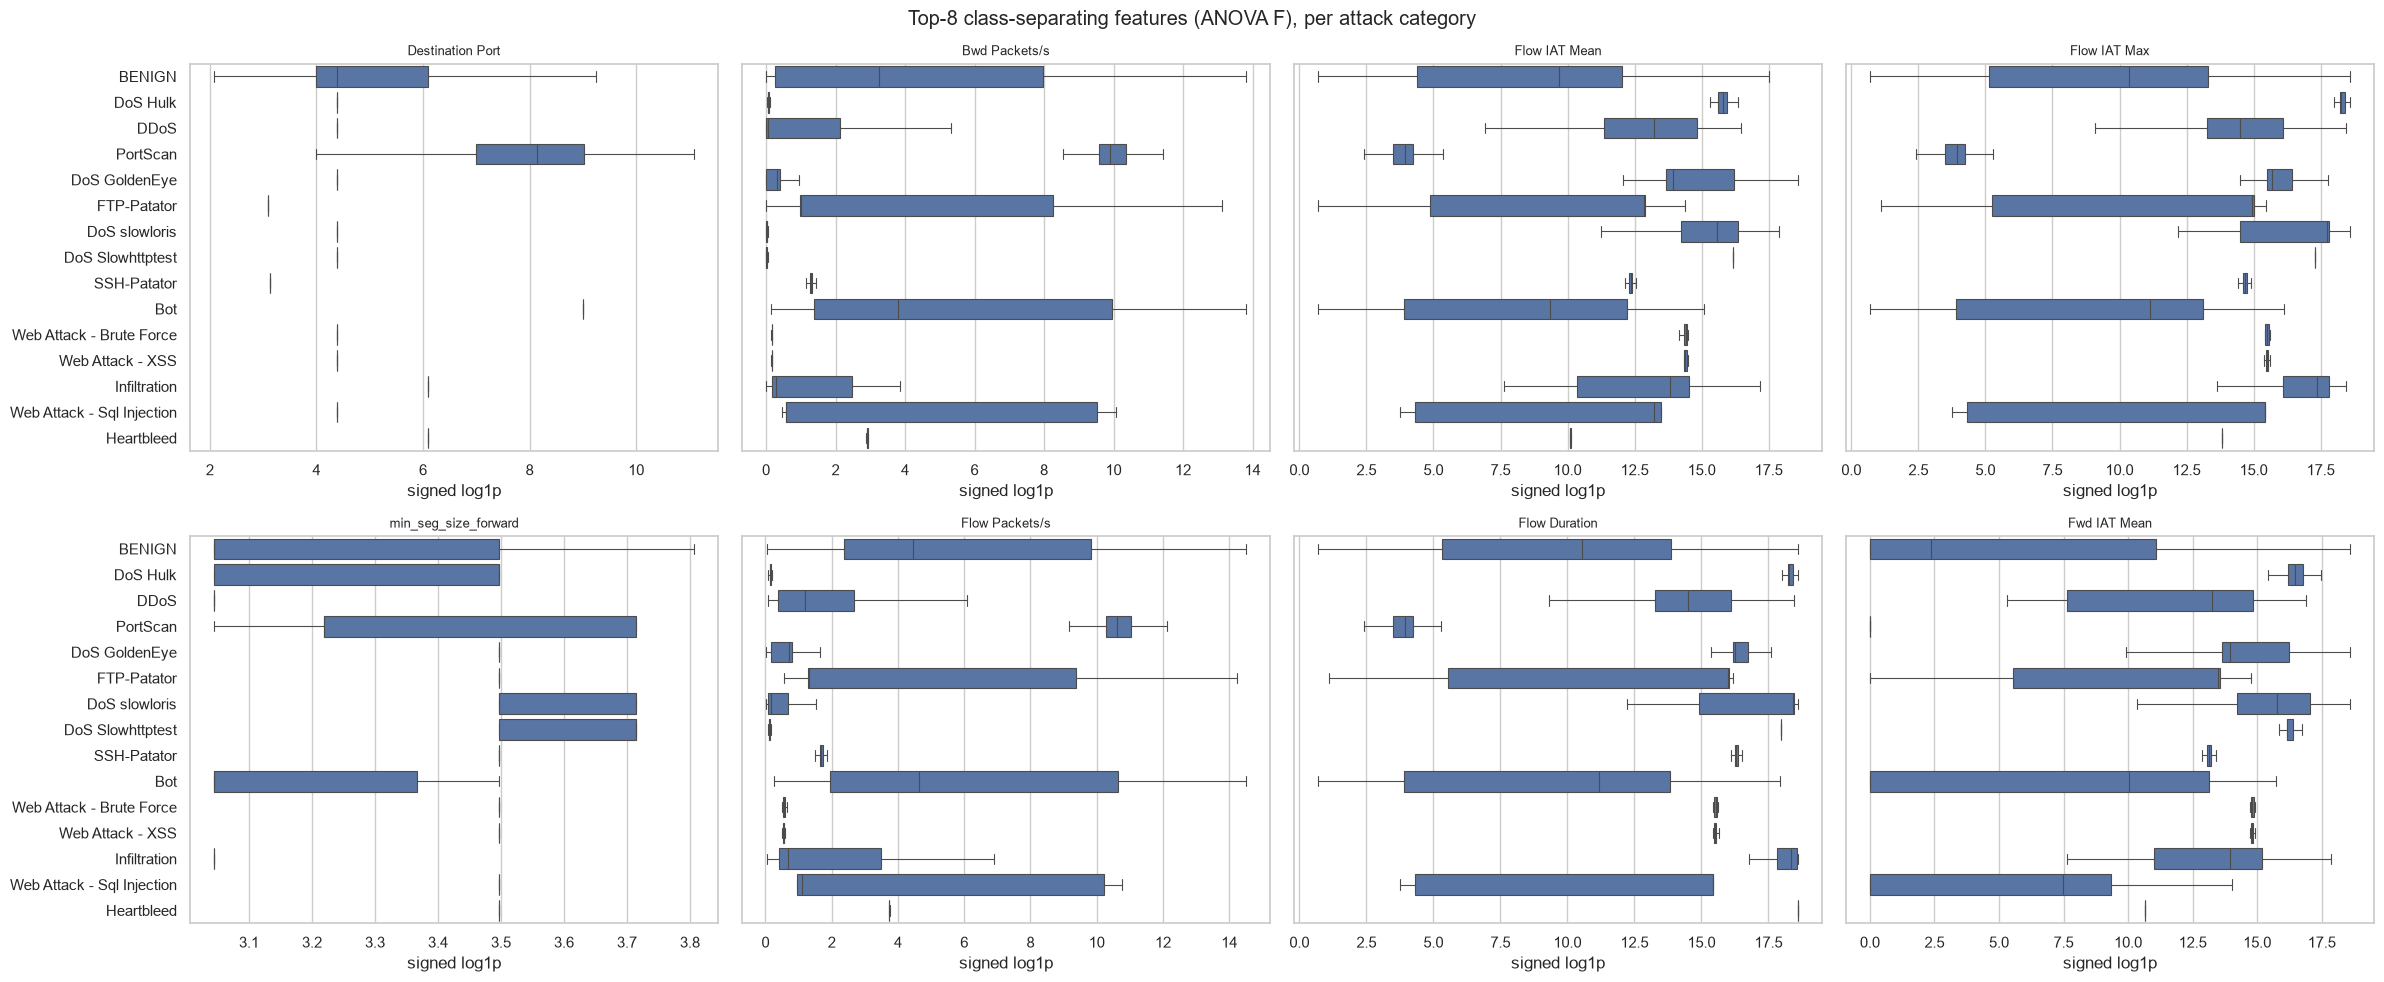

1258

In [13]:
# Categorical features
cat_cols_eda = clean_df[FEATURE_COLS].select_dtypes(exclude="number").columns.tolist()
print("Categorical feature columns:", cat_cols_eda or "none (CICIDS2017 flow features are all numeric)")

# Numerical features: the 8 features that separate the classes best (ANOVA F), shown per class on a signed-log scale
codes = clean_df["Label"].astype("category").cat.codes.to_numpy()
eda_idx = cap_per_class(codes, 3000, RANDOM_STATE)
smp = clean_df.iloc[eda_idx]
Z = pd.DataFrame(signed_log1p(smp[FEATURE_COLS].to_numpy()), columns=FEATURE_COLS)
Fv = pd.Series(np.nan_to_num(f_classif(Z, smp["Label"].to_numpy())[0]), index=FEATURE_COLS)
top8 = Fv.sort_values(ascending=False).head(8).index
Z["Label"] = smp["Label"].to_numpy(); order = list(lab_counts.index)
fig, axes = plt.subplots(2, 4, figsize=(24, 10))
for j, (a, c) in enumerate(zip(axes.ravel(), top8)):
    sns.boxplot(data=Z, x=c, y="Label", order=order, ax=a, showfliers=False, linewidth=.8)
    a.set_title(c, fontsize=9); a.set_xlabel("signed log1p"); a.set_ylabel("")
    if j % 4: a.tick_params(labelleft=False)
fig.suptitle("Top-8 class-separating features (ANOVA F), per attack category")
show("eda_numeric_features")
del smp, Z; gc.collect()

## 07 · Define multiclass target
`Label` → attack category. The three web-attack labels are merged into **Web Attack**; any label outside the workflow's list becomes **Other Attack Classes**. Class order is fixed (BENIGN = 0).

In [14]:
CLASS_ORDER = ["BENIGN", "DDoS", "DoS Hulk", "DoS GoldenEye", "DoS slowloris", "DoS Slowhttptest", "PortScan", "Bot",
               "FTP-Patator", "SSH-Patator", "Web Attack", "Infiltration", "Heartbleed", "Other Attack Classes"]
_canon = {"benign": "BENIGN", "ddos": "DDoS", "dos hulk": "DoS Hulk", "dos goldeneye": "DoS GoldenEye", "dos slowloris": "DoS slowloris",
          "dos slowhttptest": "DoS Slowhttptest", "portscan": "PortScan", "bot": "Bot", "ftp-patator": "FTP-Patator",
          "ssh-patator": "SSH-Patator", "infiltration": "Infiltration", "heartbleed": "Heartbleed"}

def to_category(raw):
    r = raw.strip().lower()
    if r.startswith("web attack"): return "Web Attack"
    return _canon.get(r, "Other Attack Classes")

label_map = {r: to_category(r) for r in clean_df["Label"].unique()}
clean_df["Attack_Category"] = clean_df["Label"].map(label_map)
display(pd.DataFrame({"raw label": list(label_map), "-> category": list(label_map.values())}).sort_values("-> category").reset_index(drop=True))

CLASS_NAMES = [c for c in CLASS_ORDER if (clean_df["Attack_Category"] == c).any()]     # classes that actually exist
CLASS_ID    = {c: i for i, c in enumerate(CLASS_NAMES)}
N_CLASSES   = len(CLASS_NAMES)
absent = [c for c in CLASS_ORDER if c not in CLASS_NAMES]
print(f"{N_CLASSES} classes present: {CLASS_NAMES}")
if absent: print("In the workflow list but not present in this dataset (handled gracefully):", absent)

cat_counts = clean_df["Attack_Category"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)
display(pd.DataFrame({"count": cat_counts, "percent": (cat_counts / cat_counts.sum() * 100).round(3)}))

,raw label,-> category
0,BENIGN,BENIGN
1,Bot,Bot
2,DDoS,DDoS
3,DoS GoldenEye,DoS GoldenEye
4,DoS Hulk,DoS Hulk
5,DoS Slowhttptest,DoS Slowhttptest
6,DoS slowloris,DoS slowloris
7,FTP-Patator,FTP-Patator
8,Heartbleed,Heartbleed
9,Infiltration,Infiltration


13 classes present: ['BENIGN', 'DDoS', 'DoS Hulk', 'DoS GoldenEye', 'DoS slowloris', 'DoS Slowhttptest', 'PortScan', 'Bot', 'FTP-Patator', 'SSH-Patator', 'Web Attack', 'Infiltration', 'Heartbleed']
In the workflow list but not present in this dataset (handled gracefully): ['Other Attack Classes']


,count,percent
Attack_Category,,
BENIGN,2094950,83.1100
DDoS,128014,5.0790
DoS Hulk,172846,6.8570
DoS GoldenEye,10286,0.4080
DoS slowloris,5385,0.2140
DoS Slowhttptest,5228,0.2070
PortScan,90694,3.5980
Bot,1948,0.0770
FTP-Patator,5931,0.2350


## 08 · X / y separation

In [15]:
X = clean_df[FEATURE_COLS].copy()
y_name = clean_df["Attack_Category"].copy()          # y = attack category (text)
print("X (network traffic features):", X.shape, "| y (attack category):", y_name.shape)

X (network traffic features): (2520691, 70) | y (attack category): (2520691,)


## 09 · Identify data types

In [16]:
numerical_features   = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print(f"numerical: {len(numerical_features)} | categorical: {len(categorical_features)}")

numerical: 70 | categorical: 0


## 10 · Encode features
One-hot only if categorical feature columns exist (none for CICIDS2017). The target is label-encoded with the fixed class order, so **BENIGN = 0** and the ids match `CLASS_NAMES`.

In [17]:
if categorical_features:
    X = pd.get_dummies(X, columns=categorical_features, dtype="float32")
    print("one-hot encoded ->", X.shape)
else:
    print("No categorical features -> one-hot encoding not needed.")

label_encoder = LabelEncoder()
label_encoder.classes_ = np.array(CLASS_NAMES, dtype=object)           # fixed order (plain .fit would sort alphabetically)
y = y_name.map(CLASS_ID).to_numpy().astype("int64")
assert (label_encoder.inverse_transform(y[:1000]) == y_name.iloc[:1000].to_numpy()).all()
print("classes:", dict(zip(label_encoder.classes_, range(N_CLASSES))))
del clean_df; gc.collect()

No categorical features -> one-hot encoding not needed.
classes: {'BENIGN': 0, 'DDoS': 1, 'DoS Hulk': 2, 'DoS GoldenEye': 3, 'DoS slowloris': 4, 'DoS Slowhttptest': 5, 'PortScan': 6, 'Bot': 7, 'FTP-Patator': 8, 'SSH-Patator': 9, 'Web Attack': 10, 'Infiltration': 11, 'Heartbleed': 12}


0

## 11 · Train / validation / test split (stratified 70 / 15 / 15)
Stratified on the 14-way target, so every class (even Heartbleed) appears in every split. The test set is locked until step 26. The training split is then capped **per class** (`CLASS_CAP`) so every experiment uses identical real training data.

In [18]:
assert np.bincount(y).min() >= 3, "a class has <3 rows after cleaning - cannot stratify; merge it into 'Other Attack Classes'"
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE)
X_train_full, X_val, y_train_full, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=RANDOM_STATE)

keep = cap_per_class(y_train_full, CLASS_CAP)
X_train, y_train = X_train_full.iloc[keep].reset_index(drop=True), y_train_full[keep]
X_val, X_test = X_val.reset_index(drop=True), X_test.reset_index(drop=True)

split_tbl = pd.DataFrame({
    "train_full": np.bincount(y_train_full, minlength=N_CLASSES), "train (used)": np.bincount(y_train, minlength=N_CLASSES),
    "validation": np.bincount(y_val, minlength=N_CLASSES), "test": np.bincount(y_test, minlength=N_CLASSES)}, index=CLASS_NAMES)
display(split_tbl.assign(**{"total": split_tbl[["train_full", "validation", "test"]].sum(axis=1)}))
print(f"train rows used: {len(y_train):,} of {len(y_train_full):,}   (validation / test keep the natural class distribution)")
for v in ("X", "X_tmp"): globals().pop(v, None)
gc.collect()

,train_full,train (used),validation,test,total
BENIGN,1466464,60000,314243,314243,2094950
DDoS,89610,60000,19202,19202,128014
DoS Hulk,120992,60000,25927,25927,172846
DoS GoldenEye,7200,7200,1543,1543,10286
DoS slowloris,3769,3769,808,808,5385
DoS Slowhttptest,3660,3660,784,784,5228
PortScan,63486,60000,13604,13604,90694
Bot,1364,1364,292,292,1948
FTP-Patator,4151,4151,890,890,5931
SSH-Patator,2253,2253,483,483,3219


train rows used: 263,931 of 1,764,483   (validation / test keep the natural class distribution)


0

## 12 · Feature scaling
`signed log1p` (tames the extreme tails of byte/packet/IAT features) followed by `StandardScaler`, **fit on the training split only**. Tree models are invariant to this monotone transform; it matters for Logistic Regression, the GAN and SMOTE's distance metric.

In [19]:
preprocessor = Pipeline([
    ("signed_log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler()),
]).set_output(transform="pandas")

X_train_s = preprocessor.fit_transform(X_train).astype("float32")
X_val_s   = preprocessor.transform(X_val).astype("float32")
X_test_s  = preprocessor.transform(X_test).astype("float32")
print("scaled train  mean|std (first 5 features):", X_train_s.mean().head().round(3).tolist(), X_train_s.std().head().round(3).tolist())

scaled train  mean|std (first 5 features): [-0.0, 0.0, -0.0, -0.0, 0.0] [1.0, 1.0, 1.0, 1.0, 1.0]


## 13 · Multiclass class-imbalance analysis
Class counts, percentages and the **minority classes** — the ones below `OVERSAMPLE_TARGET` — which SMOTE and the GAN will oversample.

,count,percent,imbalance vs largest,minority
BENIGN,60000,22.7330,1.0000,False
DDoS,60000,22.7330,1.0000,False
DoS Hulk,60000,22.7330,1.0000,False
DoS GoldenEye,7200,2.7280,8.3000,True
DoS slowloris,3769,1.4280,15.9000,True
DoS Slowhttptest,3660,1.3870,16.4000,True
PortScan,60000,22.7330,1.0000,False
Bot,1364,0.5170,44.0000,True
FTP-Patator,4151,1.5730,14.5000,True
SSH-Patator,2253,0.8540,26.6000,True


9 minority classes (< 10,000 train rows): ['DoS GoldenEye', 'DoS slowloris', 'DoS Slowhttptest', 'Bot', 'FTP-Patator', 'SSH-Patator', 'Web Attack', 'Infiltration', 'Heartbleed']


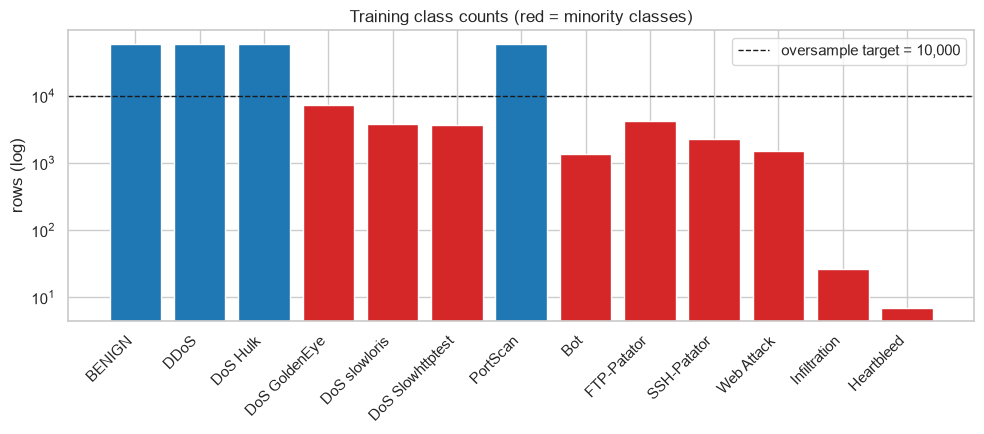

In [20]:
train_counts = pd.Series(np.bincount(y_train, minlength=N_CLASSES), index=CLASS_NAMES)
imb = pd.DataFrame({"count": train_counts, "percent": (train_counts / train_counts.sum() * 100).round(3),
                    "imbalance vs largest": (train_counts.max() / train_counts).round(1)})
imb["minority"] = imb["count"] < OVERSAMPLE_TARGET
display(imb)
MINORITY_IDS = [CLASS_ID[c] for c in CLASS_NAMES if train_counts[c] < OVERSAMPLE_TARGET]
print(f"{len(MINORITY_IDS)} minority classes (< {OVERSAMPLE_TARGET:,} train rows): {[CLASS_NAMES[i] for i in MINORITY_IDS]}")

plt.figure(figsize=(10, 4.5))
cols = ["tab:red" if c < OVERSAMPLE_TARGET else "tab:blue" for c in train_counts.values]
plt.bar(train_counts.index, train_counts.values, color=cols); plt.yscale("log"); plt.xticks(rotation=45, ha="right")
plt.axhline(OVERSAMPLE_TARGET, color="k", ls="--", lw=1, label=f"oversample target = {OVERSAMPLE_TARGET:,}"); plt.legend()
plt.title("Training class counts (red = minority classes)"); plt.ylabel("rows (log)")
show("class_imbalance_train")

## 14 · Feature selection
Correlation pruning → Random-Forest importance (multiclass RF on a class-capped sample so rare classes still influence the ranking). Both computed on **training data only**.

34 features dropped for |r| > 0.95; 36 remain
selected 25 features covering 95.4% of RF importance


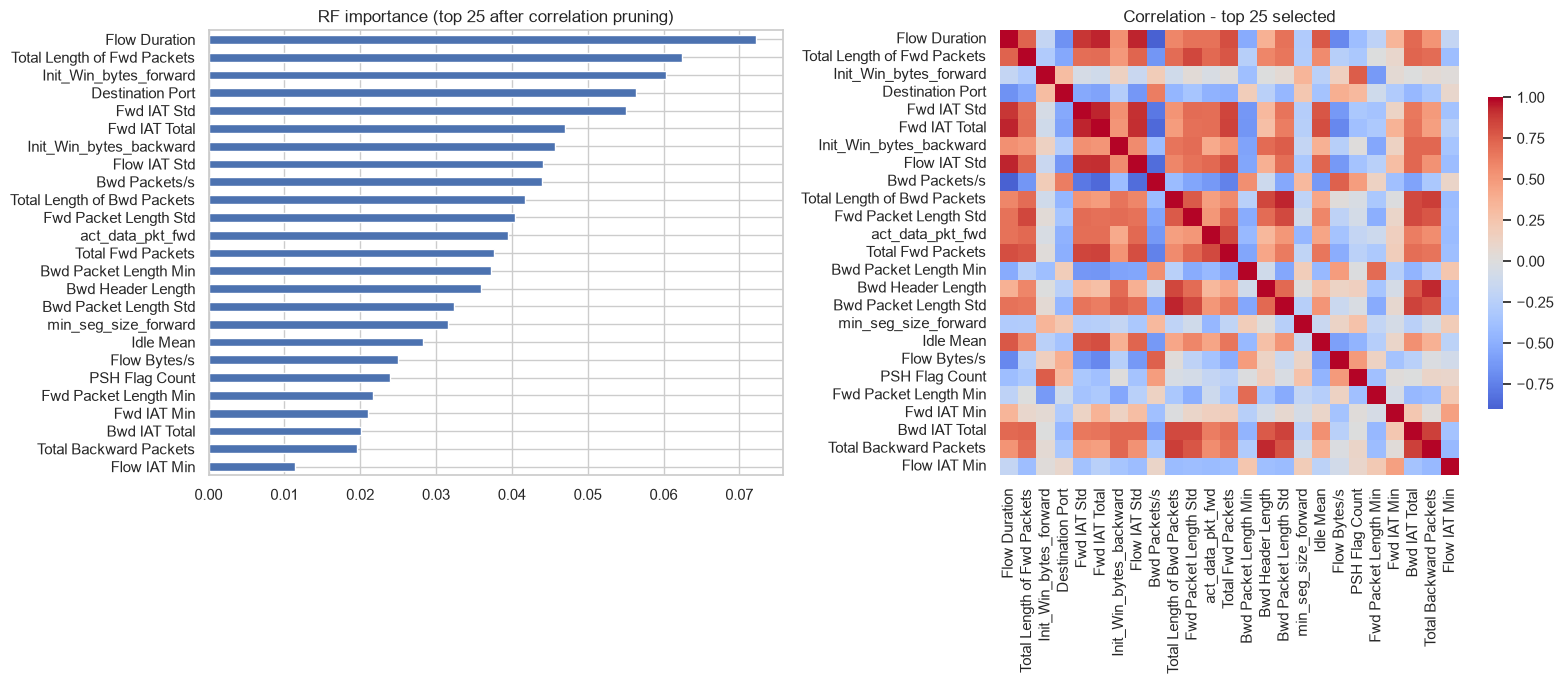

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
selected_features,Flow Duration,Total Length of Fwd Packets,Init_Win_bytes_forward,Destination Port,Fwd IAT Std,Fwd IAT Total,Init_Win_bytes_backward,Flow IAT Std,Bwd Packets/s,Total Length of Bwd Packets,Fwd Packet Length Std,act_data_pkt_fwd,Total Fwd Packets,Bwd Packet Length Min,Bwd Header Length,Bwd Packet Length Std,min_seg_size_forward,Idle Mean,Flow Bytes/s,PSH Flag Count,Fwd Packet Length Min,Fwd IAT Min,Bwd IAT Total,Total Backward Packets,Flow IAT Min


In [21]:
s = X_train_s.sample(min(100_000, len(X_train_s)), random_state=RANDOM_STATE)
corr = s.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
drop_corr = [c for c in upper.columns if (upper[c] > CORR_THRESHOLD).any()]
kept = [c for c in X_train_s.columns if c not in drop_corr]
print(f"{len(drop_corr)} features dropped for |r| > {CORR_THRESHOLD}; {len(kept)} remain")

fs_idx = cap_per_class(y_train, FS_PER_CLASS)
rf_sel = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf_sel.fit(X_train_s.iloc[fs_idx][kept], y_train[fs_idx])
imp = pd.Series(rf_sel.feature_importances_, index=kept).sort_values(ascending=False)
n_keep = max(20, int(np.searchsorted(imp.cumsum().values, IMPORTANCE_CUM)) + 1)
selected_features = imp.index[:n_keep].tolist()
print(f"selected {len(selected_features)} features covering {imp.iloc[:n_keep].sum():.1%} of RF importance")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
imp.head(25)[::-1].plot.barh(ax=ax[0]); ax[0].set_title("RF importance (top 25 after correlation pruning)")
top_c = imp.index[:25]
sns.heatmap(s[top_c].corr(), cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"shrink": .7}); ax[1].set_title("Correlation - top 25 selected")
show("feature_selection")

X_train_sel, X_val_sel, X_test_sel = X_train_s[selected_features], X_val_s[selected_features], X_test_s[selected_features]
display(pd.Series(selected_features, name="selected_features").to_frame().T)

## 15 · BASELINE — original (imbalanced) data
Shared helpers: multiclass metrics (accuracy, macro / weighted P-R-F1, one-vs-rest ROC-AUC and PR-AUC, MCC), one `evaluate` function and a `registry` of every fitted model so later steps can reuse them. Macro metrics treat all classes equally, so they are the ones that expose rare-class failures.

In [22]:
results, registry = [], {}          # results: one dict per (scenario, model, split); registry: fitted models
LABELS = np.arange(N_CLASSES)
METRIC_COLS = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_precision", "weighted_recall", "weighted_f1", "roc_auc", "pr_auc", "mcc"]

def multiclass_metrics(y_true, proba):
    pred = proba.argmax(axis=1)
    yb = label_binarize(y_true, classes=LABELS)
    aucs, aps = [], []
    for k in LABELS:                                   # one-vs-rest, only for classes present in y_true
        pos = yb[:, k].sum()
        if 0 < pos < len(y_true):
            aucs.append(roc_auc_score(yb[:, k], proba[:, k])); aps.append(average_precision_score(yb[:, k], proba[:, k]))
    kw = dict(labels=LABELS, zero_division=0)
    return dict(
        accuracy=accuracy_score(y_true, pred), balanced_accuracy=balanced_accuracy_score(y_true, pred),
        macro_precision=precision_score(y_true, pred, average="macro", **kw), macro_recall=recall_score(y_true, pred, average="macro", **kw),
        macro_f1=f1_score(y_true, pred, average="macro", **kw),
        weighted_precision=precision_score(y_true, pred, average="weighted", **kw), weighted_recall=recall_score(y_true, pred, average="weighted", **kw),
        weighted_f1=f1_score(y_true, pred, average="weighted", **kw),
        roc_auc=float(np.mean(aucs)), pr_auc=float(np.mean(aps)), mcc=matthews_corrcoef(y_true, pred),
        errors=int((pred != y_true).sum()),
    )

def evaluate(model, X_, y_, scenario, name, split):
    return dict(scenario=scenario, model=name, split=split, **multiclass_metrics(y_, model.predict_proba(X_)))

def fit_and_log(model, name, scenario, Xtr, ytr):
    t0 = time.time(); model.fit(Xtr, ytr); dt = time.time() - t0
    assert list(model.classes_) == list(range(N_CLASSES)), f"{name}: not every class was seen in training"
    registry[(scenario, name)] = model
    row = evaluate(model, X_val_sel, y_val, scenario, name, "validation"); row["fit_time_s"] = round(dt, 1)
    results.append(row); print(f"[{scenario}] {name:<28s} acc={row['accuracy']:.4f}  macroF1={row['macro_f1']:.4f}  wF1={row['weighted_f1']:.4f}  MCC={row['mcc']:.4f}  ({dt:.0f}s)")
    return model

def log_ensemble(names, scenario, label="Ensemble (Soft Voting)"):
    ens = PrefitSoftVoting([registry[(scenario, n)] for n in names])
    registry[(scenario, label)] = ens
    results.append(evaluate(ens, X_val_sel, y_val, scenario, label, "validation"))
    r = results[-1]; print(f"[{scenario}] {label:<28s} acc={r['accuracy']:.4f}  macroF1={r['macro_f1']:.4f}  wF1={r['weighted_f1']:.4f}  MCC={r['mcc']:.4f}")

def make_tree_models(n=BASE_TREES, rounds=BOOST_ROUNDS):
    return {
        "Random Forest": RandomForestClassifier(n_estimators=n, n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=rounds, learning_rate=0.1, max_depth=8, tree_method="hist", n_jobs=-1, eval_metric="mlogloss", random_state=RANDOM_STATE),
        "LightGBM": LGBMClassifier(n_estimators=rounds, learning_rate=0.1, num_leaves=63, subsample_freq=1, subsample=0.9, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE),
    }
TREE_NAMES = ["Random Forest", "XGBoost", "LightGBM"]

SC = "Original"
fit_and_log(LogisticRegression(max_iter=500, random_state=RANDOM_STATE), "Logistic Regression", SC, X_train_sel, y_train)
fit_and_log(DecisionTreeClassifier(random_state=RANDOM_STATE), "Decision Tree", SC, X_train_sel, y_train)
for n_, m_ in make_tree_models().items(): fit_and_log(m_, n_, SC, X_train_sel, y_train)
log_ensemble(TREE_NAMES, SC)       # extra row: soft-voting of the 3 original tree models (used in steps 25-27)

[Original] Logistic Regression          acc=0.9854  macroF1=0.7247  wF1=0.9865  MCC=0.9538  (8s)
[Original] Decision Tree                acc=0.9974  macroF1=0.8922  wF1=0.9976  MCC=0.9915  (2s)
[Original] Random Forest                acc=0.9986  macroF1=0.9268  wF1=0.9986  MCC=0.9952  (5s)
[Original] XGBoost                      acc=0.9987  macroF1=0.9697  wF1=0.9988  MCC=0.9958  (13s)
[Original] LightGBM                     acc=0.2300  macroF1=0.1748  wF1=0.2353  MCC=0.2655  (9s)
[Original] Ensemble (Soft Voting)       acc=0.9986  macroF1=0.9458  wF1=0.9986  MCC=0.9953


## 16 · SMOTE baseline (multiclass)
Every minority class is oversampled to `OVERSAMPLE_TARGET` rows with SMOTE (one-vs-rest interpolation between a class's own nearest neighbours). `k_neighbors` is reduced automatically if a class has very few rows (e.g. Heartbleed).

In [23]:
t0 = time.time()
smote_strategy = {c: OVERSAMPLE_TARGET for c in MINORITY_IDS}
k_nn = max(1, min(5, int(min(train_counts[CLASS_NAMES[c]] for c in MINORITY_IDS)) - 1))
smote = SMOTE(sampling_strategy=smote_strategy, k_neighbors=k_nn, random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_sel, y_train)
print(f"SMOTE (k={k_nn}): {len(X_train_sel):,} -> {len(X_train_smote):,} rows in {time.time()-t0:.0f}s")
display(pd.DataFrame({"before": np.bincount(y_train, minlength=N_CLASSES), "after SMOTE": np.bincount(y_train_smote, minlength=N_CLASSES)}, index=CLASS_NAMES))

SC = "SMOTE"
for n_, m_ in make_tree_models().items(): fit_and_log(m_, n_, SC, X_train_smote, y_train_smote)
log_ensemble(TREE_NAMES, SC)

SMOTE (k=5): 263,931 -> 330,000 rows in 1s


,before,after SMOTE
BENIGN,60000,60000
DDoS,60000,60000
DoS Hulk,60000,60000
DoS GoldenEye,7200,10000
DoS slowloris,3769,10000
DoS Slowhttptest,3660,10000
PortScan,60000,60000
Bot,1364,10000
FTP-Patator,4151,10000
SSH-Patator,2253,10000


[SMOTE] Random Forest                acc=0.9984  macroF1=0.9547  wF1=0.9985  MCC=0.9948  (8s)
[SMOTE] XGBoost                      acc=0.9986  macroF1=0.9421  wF1=0.9986  MCC=0.9952  (17s)
[SMOTE] LightGBM                     acc=0.9987  macroF1=0.9604  wF1=0.9987  MCC=0.9956  (15s)
[SMOTE] Ensemble (Soft Voting)       acc=0.9987  macroF1=0.9612  wF1=0.9988  MCC=0.9958


## 17 · GAN oversampling (conditional WGAN-GP)
One **conditional** WGAN-GP replaces the binary pipeline's single generator: the class one-hot is fed to both generator and critic, so a single network learns every minority class and generates exactly the class asked for. Real minority rows are drawn **class-balanced** in each batch (otherwise Bot/Web Attack would drown out Heartbleed).

- 17a identify minority classes → 17b prepare their data → 17c train → 17d generate → 17e validate **per class** → 17f combine with the real training data.
- Caution for the rarest classes (Heartbleed ≈ 7 and Infiltration ≈ 25 training rows): a GAN cannot learn a distribution from a handful of points and will mostly interpolate/memorise them. The validation table reports nearest-real-neighbour distances so you can see this.

,class,real train rows,to generate
0,DoS GoldenEye,7200,2800
1,DoS slowloris,3769,6231
2,DoS Slowhttptest,3660,6340
3,Bot,1364,8636
4,FTP-Patator,4151,5849
5,SSH-Patator,2253,7747
6,Web Attack,1501,8499
7,Infiltration,26,9974
8,Heartbleed,7,9993


iter    600/6000  critic=  -4.035  gen=  -1.003  W-dist=  4.469  (27s)
iter   1200/6000  critic=  -2.825  gen=  -1.043  W-dist=  3.184  (55s)
iter   1800/6000  critic=  -2.611  gen=  -0.627  W-dist=  2.901  (83s)
iter   2400/6000  critic=  -2.203  gen=  -0.143  W-dist=  2.484  (110s)
iter   3000/6000  critic=  -1.801  gen=  -0.722  W-dist=  2.041  (138s)
iter   3600/6000  critic=  -1.816  gen=  -0.069  W-dist=  2.045  (165s)
iter   4200/6000  critic=  -1.570  gen=   0.405  W-dist=  1.729  (193s)
iter   4800/6000  critic=  -1.469  gen=   0.251  W-dist=  1.658  (221s)
iter   5400/6000  critic=  -1.588  gen=   0.104  W-dist=  1.773  (248s)
iter   6000/6000  critic=  -1.345  gen=  -0.086  W-dist=  1.551  (275s)


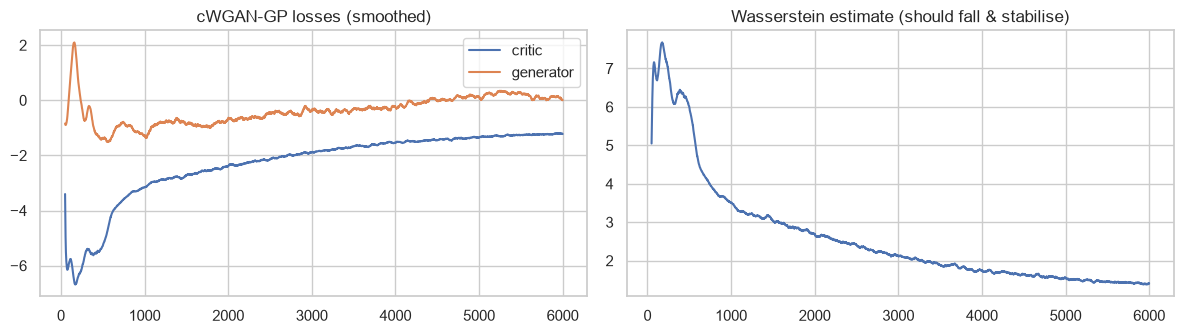

In [24]:
# ---- 17a/b. identify minority classes + prepare their data ----
K_min = len(MINORITY_IDS); cls_pos = {c: i for i, c in enumerate(MINORITY_IDS)}
n_feat = X_train_sel.shape[1]
Xm = {c: X_train_sel[y_train == c].to_numpy(np.float32) for c in MINORITY_IDS}
display(pd.DataFrame({"class": [CLASS_NAMES[c] for c in MINORITY_IDS], "real train rows": [len(Xm[c]) for c in MINORITY_IDS],
                      "to generate": [OVERSAMPLE_TARGET - len(Xm[c]) for c in MINORITY_IDS]}))

X_all = torch.from_numpy(np.vstack([Xm[c] for c in MINORITY_IDS])).to(device)
c_all = torch.from_numpy(np.concatenate([np.full(len(Xm[c]), cls_pos[c]) for c in MINORITY_IDS])).long().to(device)
samp_w = (1.0 / torch.bincount(c_all, minlength=K_min).float())[c_all]        # -> every class equally likely in a batch

# ---- 17c. conditional WGAN-GP ----
class Generator(nn.Module):
    def __init__(s, z=GAN_LATENT, k=K_min, h=256, out=n_feat):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(z + k, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, out))
    def forward(s, z, c): return s.net(torch.cat([z, Fnn.one_hot(c, K_min).float()], dim=1))

class Critic(nn.Module):
    def __init__(s, inp=n_feat, k=K_min, h=256):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(inp + k, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, 1))
    def forward(s, x, c): return s.net(torch.cat([x, Fnn.one_hot(c, K_min).float()], dim=1))

def gradient_penalty(critic, real, fake, c):
    a = torch.rand(real.size(0), 1, device=device)
    xi = (a * real + (1 - a) * fake).requires_grad_(True)
    g = torch.autograd.grad(critic(xi, c).sum(), xi, create_graph=True)[0]
    return ((g.norm(2, dim=1) - 1) ** 2).mean()

G, D = Generator().to(device), Critic().to(device)
optG = torch.optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.9))
optD = torch.optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.9))
N_CRITIC, LAMBDA_GP = 5, 10.0
hist = {"critic": [], "gen": [], "w_dist": []}

t0 = time.time()
for it in range(1, GAN_ITERS + 1):
    for _ in range(N_CRITIC):
        ix = torch.multinomial(samp_w, GAN_BATCH, replacement=True)
        real, lab = X_all[ix], c_all[ix]
        fake = G(torch.randn(GAN_BATCH, GAN_LATENT, device=device), lab).detach()
        d_real, d_fake = D(real, lab).mean(), D(fake, lab).mean()
        loss_d = d_fake - d_real + LAMBDA_GP * gradient_penalty(D, real, fake, lab)
        optD.zero_grad(); loss_d.backward(); optD.step()
    lab = c_all[torch.multinomial(samp_w, GAN_BATCH, replacement=True)]
    loss_g = -D(G(torch.randn(GAN_BATCH, GAN_LATENT, device=device), lab), lab).mean()
    optG.zero_grad(); loss_g.backward(); optG.step()
    hist["critic"].append(loss_d.item()); hist["gen"].append(loss_g.item()); hist["w_dist"].append((d_real - d_fake).item())
    if it % max(1, GAN_ITERS // 10) == 0:
        print(f"iter {it:>6}/{GAN_ITERS}  critic={loss_d.item():8.3f}  gen={loss_g.item():8.3f}  W-dist={hist['w_dist'][-1]:7.3f}  ({time.time()-t0:.0f}s)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(pd.Series(hist["critic"]).rolling(50).mean(), label="critic"); ax[0].plot(pd.Series(hist["gen"]).rolling(50).mean(), label="generator"); ax[0].legend(); ax[0].set_title("cWGAN-GP losses (smoothed)")
ax[1].plot(pd.Series(hist["w_dist"]).rolling(50).mean()); ax[1].set_title("Wasserstein estimate (should fall & stabilise)")
show("gan_training")

In [25]:
# ---- 17d. generate synthetic samples, class by class, up to OVERSAMPLE_TARGET ----
G.eval(); syn_X, syn_y = [], []
with torch.no_grad():
    for c in MINORITY_IDS:
        need = OVERSAMPLE_TARGET - len(Xm[c])
        if need <= 0: continue
        out = []
        for i in range(0, need, 50_000):
            b = min(50_000, need - i)
            lab = torch.full((b,), cls_pos[c], dtype=torch.long, device=device)
            out.append(G(torch.randn(b, GAN_LATENT, device=device), lab).cpu().numpy())
        arr = np.clip(np.vstack(out), Xm[c].min(0), Xm[c].max(0)).astype("float32")      # keep inside that class's real range
        syn_X.append(arr); syn_y.append(np.full(len(arr), c))
X_syn, y_syn = np.vstack(syn_X), np.concatenate(syn_y)
print("synthetic samples:", X_syn.shape)

synthetic samples: (66069, 25)


e:\BRM003-ML-Project\brmenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\BRM003-ML-Project\brmenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
e:\BRM003-ML-Project\brmenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\BRM003-ML-Project\brmenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
e:\BRM003-ML-Project\brmenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
e:\BRM003-ML-Project\brmenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
e:\BRM003-ML-Project\brmenv\Lib\site-pac

,n_real,n_syn,mean KS (low=good),corr gap (low=good),real-vs-fake AUC (0.5=good),NN dist synthetic,NN dist real-real
class,,,,,,,
DoS GoldenEye,7200,2800,0.2760,0.1225,1.0000,0.7317,0.0697
DoS slowloris,3769,6231,0.3263,0.2366,1.0000,1.3479,0.0261
DoS Slowhttptest,3660,6340,0.4053,0.2152,1.0000,1.1863,0.0240
Bot,1364,8636,0.3304,0.1789,1.0000,1.1523,0.0359
FTP-Patator,4151,5849,0.3024,0.0272,1.0000,0.4899,0.0153
SSH-Patator,2253,7747,0.4147,0.2558,1.0000,0.4555,0.0316
Web Attack,1501,8499,0.3693,0.1726,1.0000,0.4750,0.0237
Infiltration,26,9974,0.2771,0.1377,NaN,1.6367,1.6118
Heartbleed,7,9993,0.3386,NaN,NaN,0.4251,0.6459


NN dist synthetic << NN dist real-real  =>  synthetic rows sit on top of real ones (memorisation). Expect this for the tiniest classes.


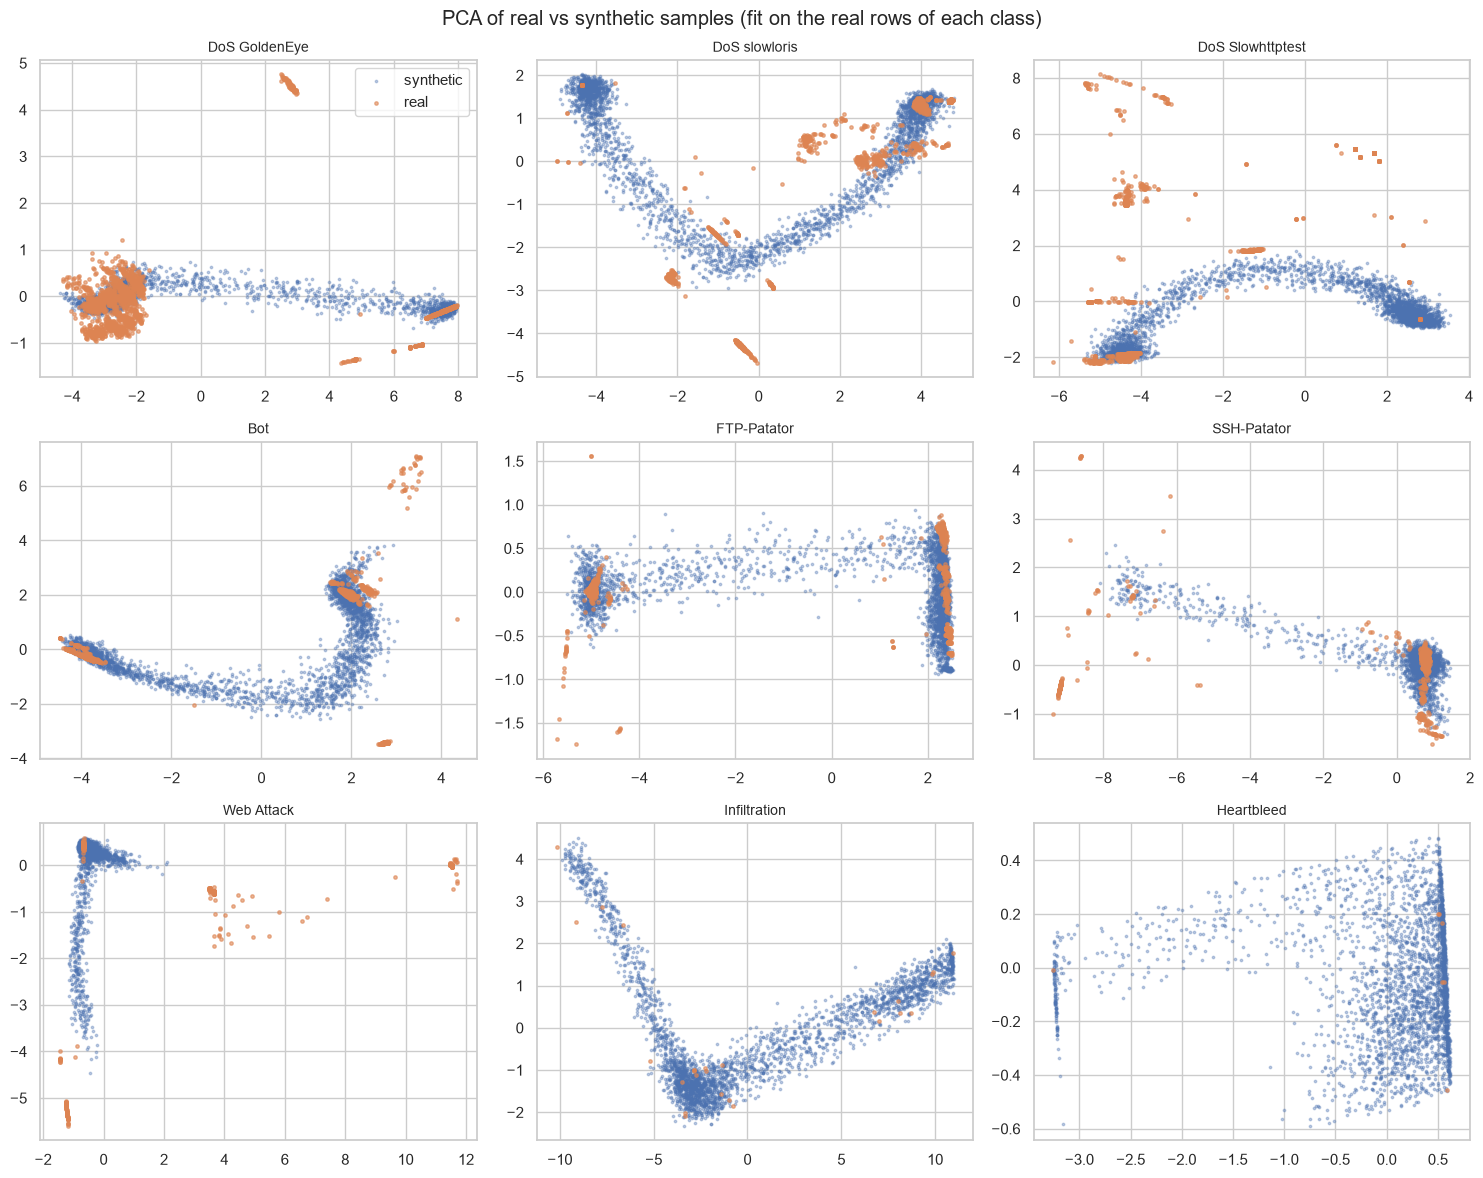

In [26]:
# ---- 17e. validate synthetic samples PER CLASS (real vs synthetic) ----
rng = np.random.default_rng(RANDOM_STATE); rows = []
for c in MINORITY_IDS:
    Rall = Xm[c]; Sall = X_syn[y_syn == c]
    R = Rall[rng.choice(len(Rall), min(5000, len(Rall)), replace=False)]; S = Sall[rng.choice(len(Sall), min(5000, len(Sall)), replace=False)]
    ks = np.mean([ks_2samp(R[:, j], S[:, j]).statistic for j in range(n_feat)])
    corr_gap = np.nan_to_num(np.abs(np.corrcoef(R.T) - np.corrcoef(S.T))).mean() if len(R) >= 10 else np.nan
    disc_auc = np.nan
    if len(R) >= 100:                                        # real-vs-fake classifier (0.5 = indistinguishable); unreliable for tiny classes
        Zc = np.vstack([R, S]); zl = np.r_[np.ones(len(R)), np.zeros(len(S))]
        Ztr, Zte, ltr, lte = train_test_split(Zc, zl, test_size=0.3, stratify=zl, random_state=RANDOM_STATE)
        disc_auc = roc_auc_score(lte, RandomForestClassifier(100, n_jobs=-1, random_state=RANDOM_STATE).fit(Ztr, ltr).predict_proba(Zte)[:, 1])
    nn_ = NearestNeighbors(n_neighbors=2).fit(Rall)
    d_syn = nn_.kneighbors(S[:2000], n_neighbors=1)[0].mean()
    d_real = nn_.kneighbors(R[:2000], n_neighbors=2)[0][:, 1].mean()
    rows.append({"class": CLASS_NAMES[c], "n_real": len(Rall), "n_syn": len(Sall), "mean KS (low=good)": ks, "corr gap (low=good)": corr_gap,
                 "real-vs-fake AUC (0.5=good)": disc_auc, "NN dist synthetic": d_syn, "NN dist real-real": d_real})
gan_val = pd.DataFrame(rows).set_index("class"); display(gan_val)
print("NN dist synthetic << NN dist real-real  =>  synthetic rows sit on top of real ones (memorisation). Expect this for the tiniest classes.")

n_c = len(MINORITY_IDS); ncol = 3; nrow = math.ceil(n_c / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow), squeeze=False)
for a, c in zip(axes.ravel(), MINORITY_IDS):
    R = Xm[c][:3000]; S = X_syn[y_syn == c][:3000]; pca = PCA(2, random_state=RANDOM_STATE).fit(R)
    a.scatter(*pca.transform(S).T, s=3, alpha=.35, label="synthetic"); a.scatter(*pca.transform(R).T, s=6, alpha=.6, label="real"); a.set_title(CLASS_NAMES[c], fontsize=10)
axes.ravel()[0].legend()
for a in axes.ravel()[n_c:]: a.axis("off")
fig.suptitle("PCA of real vs synthetic samples (fit on the real rows of each class)")
show("gan_validation_pca")

In [27]:
# ---- 17f. combine real + synthetic (training data only) ----
X_train_gan = pd.concat([X_train_sel, pd.DataFrame(X_syn, columns=selected_features)], ignore_index=True)
y_train_gan = np.r_[y_train, y_syn]
print(f"GAN-balanced train: {len(X_train_gan):,} rows  (real {len(X_train_sel):,} + synthetic {len(X_syn):,})")
display(pd.DataFrame({"real": np.bincount(y_train, minlength=N_CLASSES), "synthetic": np.bincount(y_syn, minlength=N_CLASSES),
                      "total": np.bincount(y_train_gan, minlength=N_CLASSES)}, index=CLASS_NAMES))

GAN-balanced train: 330,000 rows  (real 263,931 + synthetic 66,069)


,real,synthetic,total
BENIGN,60000,0,60000
DDoS,60000,0,60000
DoS Hulk,60000,0,60000
DoS GoldenEye,7200,2800,10000
DoS slowloris,3769,6231,10000
DoS Slowhttptest,3660,6340,10000
PortScan,60000,0,60000
Bot,1364,8636,10000
FTP-Patator,4151,5849,10000
SSH-Patator,2253,7747,10000


## 18 · GAN-based multiclass classification (default hyper-parameters)

In [28]:
SC = "GAN"
for n_, m_ in make_tree_models().items(): fit_and_log(m_, n_, SC, X_train_gan, y_train_gan)
log_ensemble(TREE_NAMES, SC)

[GAN] Random Forest                acc=0.9986  macroF1=0.9436  wF1=0.9986  MCC=0.9952  (9s)
[GAN] XGBoost                      acc=0.9987  macroF1=0.9574  wF1=0.9988  MCC=0.9957  (17s)
[GAN] LightGBM                     acc=0.9987  macroF1=0.9625  wF1=0.9988  MCC=0.9958  (17s)
[GAN] Ensemble (Soft Voting)       acc=0.9988  macroF1=0.9595  wF1=0.9988  MCC=0.9960


## 19 · Hyper-parameter tuning (RF, XGBoost, LightGBM)
Random search on a **per-class-capped slice of the GAN-balanced training data**, scored by **macro-F1 on a real validation slice** (`PredefinedSplit`). Ordinary k-fold CV would score on synthetic rows too and reward the GAN's own artefacts. The validation slice is also capped per class so rare classes carry weight in the score. The test set is untouched.

In [29]:
it_ = cap_per_class(y_train_gan, TUNE_PER_CLASS); iv_ = cap_per_class(y_val, TUNE_VAL_PER_CLASS)
Xt, yt = X_train_gan.iloc[it_], y_train_gan[it_]
Xv, yv = X_val_sel.iloc[iv_], y_val[iv_]
X_search, y_search = pd.concat([Xt, Xv]), np.r_[yt, yv]
cv = PredefinedSplit(np.r_[-np.ones(len(Xt)), np.zeros(len(Xv))])
print(f"tuning: {len(Xt):,} GAN-balanced train rows, {len(Xv):,} real validation rows")

spaces = {
    "Random Forest": dict(n_estimators=[100, 200, 300], max_depth=[None, 20, 30], min_samples_leaf=[1, 2, 5], max_features=["sqrt", 0.3]),
    "XGBoost": dict(n_estimators=[100, 200, 300], max_depth=[6, 8, 10], learning_rate=[0.05, 0.1, 0.2], subsample=[0.7, 0.9, 1.0], colsample_bytree=[0.6, 0.8, 1.0]),
    "LightGBM": dict(n_estimators=[100, 200, 300], num_leaves=[31, 63, 127], learning_rate=[0.05, 0.1, 0.2], min_child_samples=[20, 50, 100], subsample=[0.7, 0.9, 1.0], colsample_bytree=[0.6, 0.8, 1.0]),
}
best_params = {}
for name, base in make_tree_models().items():
    t0 = time.time()
    rs = RandomizedSearchCV(base, spaces[name], n_iter=TUNE_ITER, scoring="f1_macro", cv=cv, refit=False, random_state=RANDOM_STATE, n_jobs=1)
    rs.fit(X_search, y_search)
    best_params[name] = rs.best_params_
    print(f"{name:14s} best macro-F1 {rs.best_score_:.4f} in {time.time()-t0:.0f}s -> {rs.best_params_}")
json.dump(best_params, open(OUT_DIR / "best_params.json", "w"), indent=2, default=str)

tuning: 104,000 GAN-balanced train rows, 25,128 real validation rows
Random Forest  best macro-F1 0.9486 in 60s -> {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 30}
XGBoost        best macro-F1 0.9728 in 95s -> {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.6}
LightGBM       best macro-F1 0.9892 in 51s -> {'subsample': 0.9, 'num_leaves': 63, 'n_estimators': 200, 'min_child_samples': 100, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


In [30]:
# refit the tuned models on the full GAN-balanced training set
SC = "GAN + Tuned"
for name, base in make_tree_models().items():
    fit_and_log(base.set_params(**best_params[name]), name, SC, X_train_gan, y_train_gan)

[GAN + Tuned] Random Forest                acc=0.9986  macroF1=0.9455  wF1=0.9986  MCC=0.9952  (26s)
[GAN + Tuned] XGBoost                      acc=0.9987  macroF1=0.9190  wF1=0.9987  MCC=0.9956  (40s)
[GAN + Tuned] LightGBM                     acc=0.9988  macroF1=0.9691  wF1=0.9988  MCC=0.9959  (16s)


## 20 · Ensemble classification (hard voting, soft voting, final multiclass prediction)
- **Hard voting**: each tuned model votes for one class; the majority wins (ties → highest mean probability).
- **Soft voting**: average the three class-probability vectors, take the argmax.
- The **final multiclass prediction** comes from whichever of the two has the higher **validation macro-F1** (macro-F1 so that rare classes count).

In [31]:
SC = "GAN + Tuned"
base_models = [registry[(SC, n)] for n in TREE_NAMES]

hard = PrefitHardVoting(base_models); registry[(SC, "Ensemble (Hard Voting)")] = hard
results.append(evaluate(hard, X_val_sel, y_val, SC, "Ensemble (Hard Voting)", "validation"))
log_ensemble(TREE_NAMES, SC, "Ensemble (Soft Voting)")

ens_val = pd.DataFrame([r for r in results if r["scenario"] == SC and r["model"].startswith("Ensemble")]).set_index("model")
display(ens_val[METRIC_COLS + ["errors"]])

FINAL_NAME = ens_val["macro_f1"].idxmax()
final_model = registry[(SC, FINAL_NAME)]
print(f"\nFinal ensemble chosen by validation macro-F1: {FINAL_NAME}")

[GAN + Tuned] Ensemble (Soft Voting)       acc=0.9988  macroF1=0.9705  wF1=0.9988  MCC=0.9960


,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,roc_auc,pr_auc,mcc,errors
model,,,,,,,,,,,
Ensemble (Hard Voting),0.9988,0.9668,0.9664,0.9599,0.9990,0.9988,0.9988,0.9914,0.9541,0.9960,452
Ensemble (Soft Voting),0.9988,0.9668,0.9815,0.9705,0.9990,0.9988,0.9988,0.9999,0.9775,0.9960,454



Final ensemble chosen by validation macro-F1: Ensemble (Soft Voting)


## 21 · Feature importance (RF / XGBoost / LightGBM, tuned, GAN-trained)

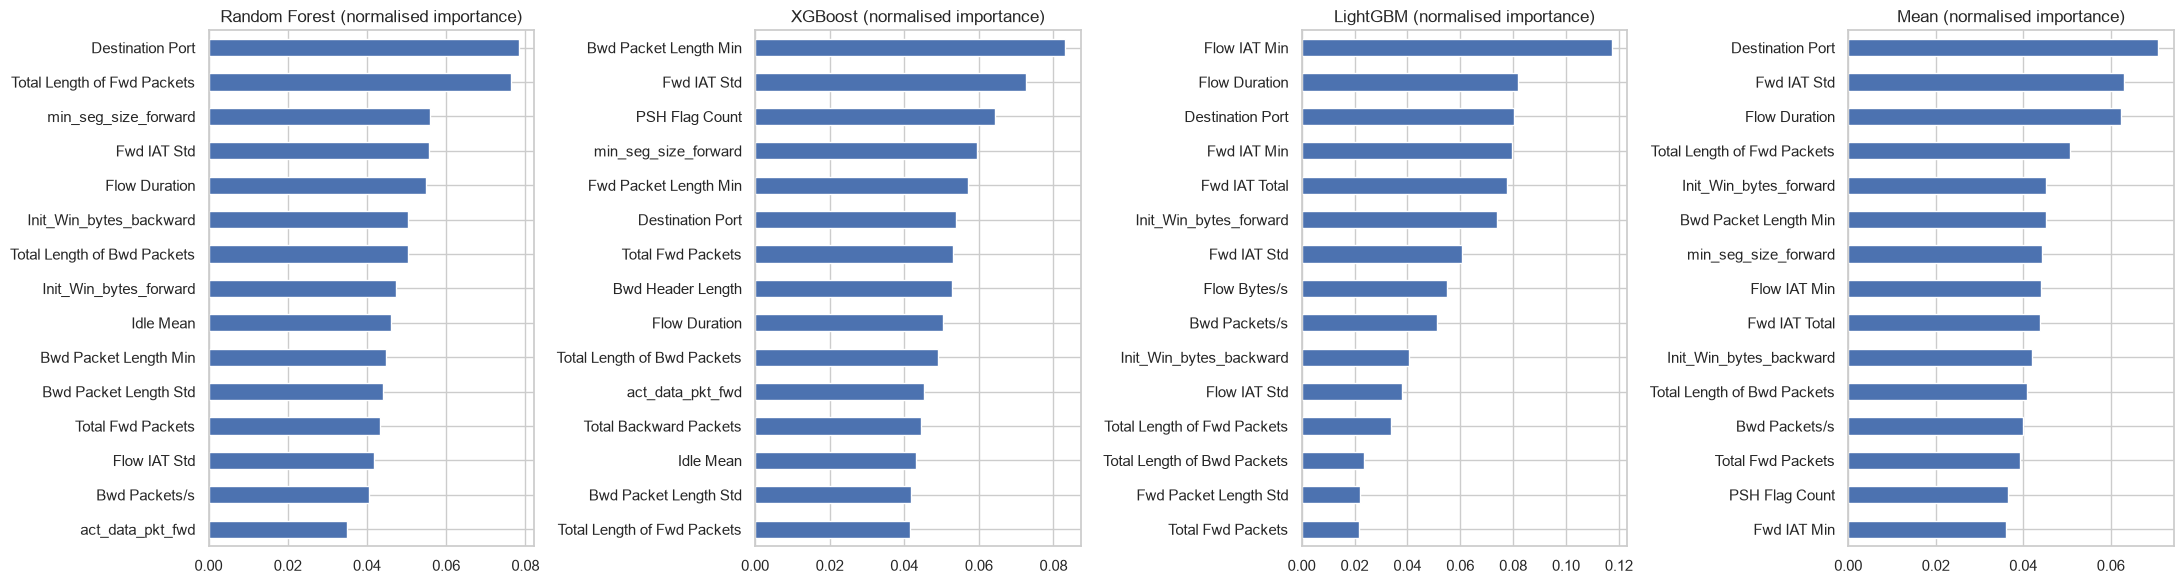

,Random Forest,XGBoost,LightGBM,Mean
Destination Port,0.0783,0.0540,0.0804,0.0709
Fwd IAT Std,0.0557,0.0725,0.0608,0.0630
Flow Duration,0.0548,0.0505,0.0817,0.0623
Total Length of Fwd Packets,0.0765,0.0414,0.0339,0.0506
Init_Win_bytes_forward,0.0474,0.0144,0.0741,0.0453
Bwd Packet Length Min,0.0447,0.0832,0.0077,0.0452
min_seg_size_forward,0.0559,0.0594,0.0179,0.0444
Flow IAT Min,0.0092,0.0054,0.1174,0.0440
Fwd IAT Total,0.0341,0.0200,0.0777,0.0439
Init_Win_bytes_backward,0.0503,0.0348,0.0406,0.0419


In [32]:
SC = "GAN + Tuned"
fi = pd.DataFrame({n: registry[(SC, n)].feature_importances_ for n in TREE_NAMES}, index=selected_features)
fi = fi / fi.sum()
fi["Mean"] = fi.mean(axis=1)
fi = fi.sort_values("Mean", ascending=False)
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, n in zip(ax, TREE_NAMES + ["Mean"]):
    fi[n].sort_values().tail(15).plot.barh(ax=a); a.set_title(f"{n} (normalised importance)")
show("feature_importance")
fi.to_csv(OUT_DIR / "feature_importance.csv"); display(fi.head(15))

## 22 · SHAP explainability (TreeExplainer, multiclass)
SHAP is computed for each tuned tree model on a **class-stratified sample of the test set** (`SHAP_PER_CLASS` rows per class, so rare attacks are represented; the plots describe this sample, not the natural class mix). For a multiclass model SHAP returns one explanation per class: the contribution of every feature to that class's score (log-odds for XGBoost/LightGBM, probability for Random Forest — so global importances are normalised per model before averaging).

- **Global**: which features matter overall.  **Class-wise**: which features drive each attack category.  **Local**: why one specific flow got its label.

In [33]:
def shap_multiclass(model, X_):
    """-> (K, n, features) SHAP values per class, and the K base values."""
    exp = shap.TreeExplainer(model)
    sv = exp.shap_values(X_, check_additivity=False)
    sv = np.stack(sv, 0) if isinstance(sv, list) else np.transpose(np.asarray(sv), (2, 0, 1))      # newer SHAP: (n, f, K)
    return sv, np.ravel(exp.expected_value)

pick = np.random.default_rng(RANDOM_STATE).permutation(cap_per_class(y_test, SHAP_PER_CLASS))
X_shap, y_shap = X_test_sel.iloc[pick].reset_index(drop=True), y_test[pick]
rf_rows = cap_per_class(y_shap, SHAP_PER_CLASS_RF)
print("SHAP sample:", np.bincount(y_shap, minlength=N_CLASSES).tolist(), "(per class, in CLASS_NAMES order)")

SC = "GAN + Tuned"; shap_vals, shap_base = {}, {}
for n in TREE_NAMES:
    Xn = X_shap.iloc[rf_rows] if n == "Random Forest" else X_shap
    t0 = time.time(); shap_vals[n], shap_base[n] = shap_multiclass(registry[(SC, n)], Xn)
    print(f"{n}: SHAP computed on {len(Xn):,} rows x {N_CLASSES} classes in {time.time()-t0:.0f}s")

SHAP sample: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 5, 2] (per class, in CLASS_NAMES order)
Random Forest: SHAP computed on 227 rows x 13 classes in 16s
XGBoost: SHAP computed on 1,107 rows x 13 classes in 2s
LightGBM: SHAP computed on 1,107 rows x 13 classes in 6s


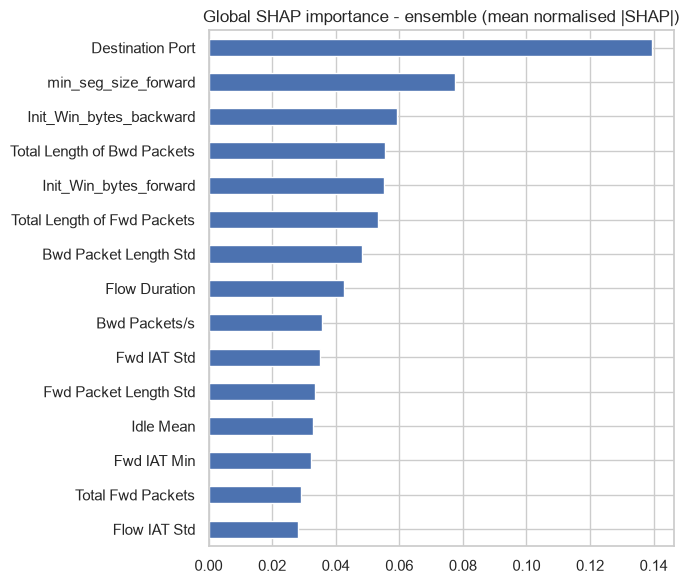

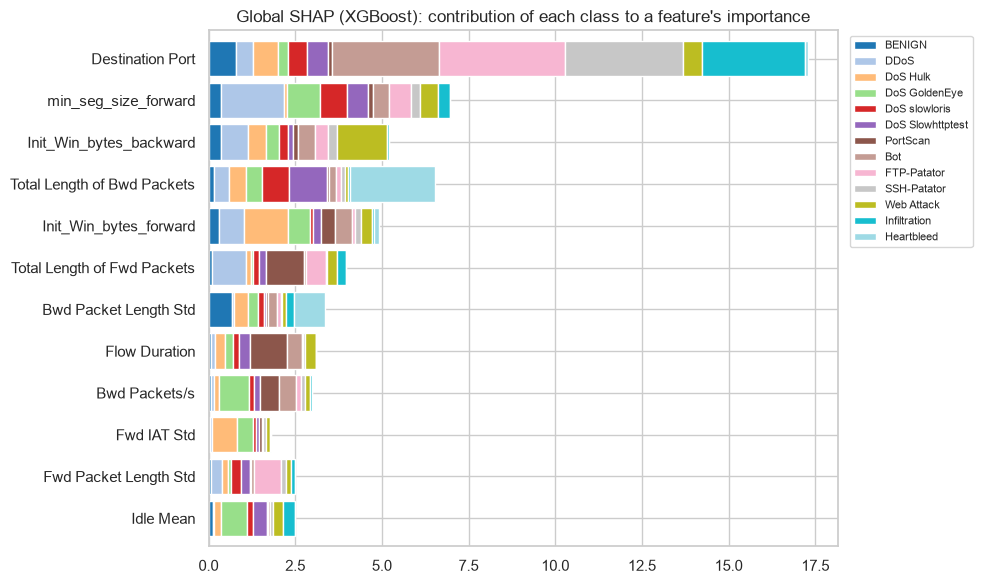

In [34]:
# ---- global explanation ----
mean_abs = pd.DataFrame({n: np.abs(shap_vals[n]).mean(axis=(0, 1)) for n in TREE_NAMES}, index=selected_features)   # mean |SHAP| over classes and rows
mean_abs = mean_abs / mean_abs.sum()
mean_abs["Ensemble (avg)"] = mean_abs.mean(axis=1)
mean_abs = mean_abs.sort_values("Ensemble (avg)", ascending=False)
mean_abs["Ensemble (avg)"].head(15)[::-1].plot.barh(figsize=(7, 6), title="Global SHAP importance - ensemble (mean normalised |SHAP|)")
show("shap_global_bar"); mean_abs.to_csv(OUT_DIR / "shap_global.csv")

# stacked bar: how much of each top feature's importance comes from which class (XGBoost)
sv_x = shap_vals["XGBoost"]
per_cls = pd.DataFrame(np.abs(sv_x).mean(axis=1).T, index=selected_features, columns=CLASS_NAMES)
per_cls.loc[mean_abs.index[:12]][::-1].plot.barh(stacked=True, figsize=(10, 6), colormap="tab20", width=.85)
plt.title("Global SHAP (XGBoost): contribution of each class to a feature's importance"); plt.legend(bbox_to_anchor=(1.01, 1), fontsize=8)
show("shap_global_stacked")

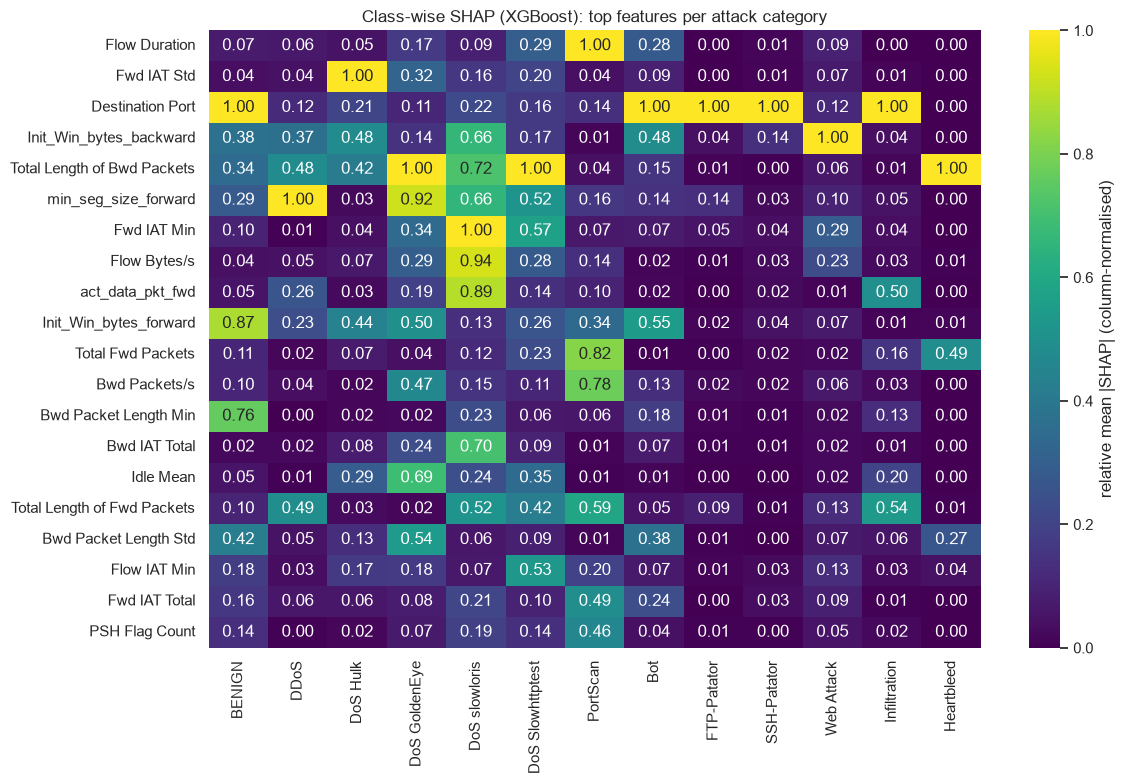

C:\Users\Surya\AppData\Local\Temp\ipykernel_15472\1534776920.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_x[k], X_shap, max_display=12, show=False); plt.title(f"SHAP summary - class '{cname}' (XGBoost)")


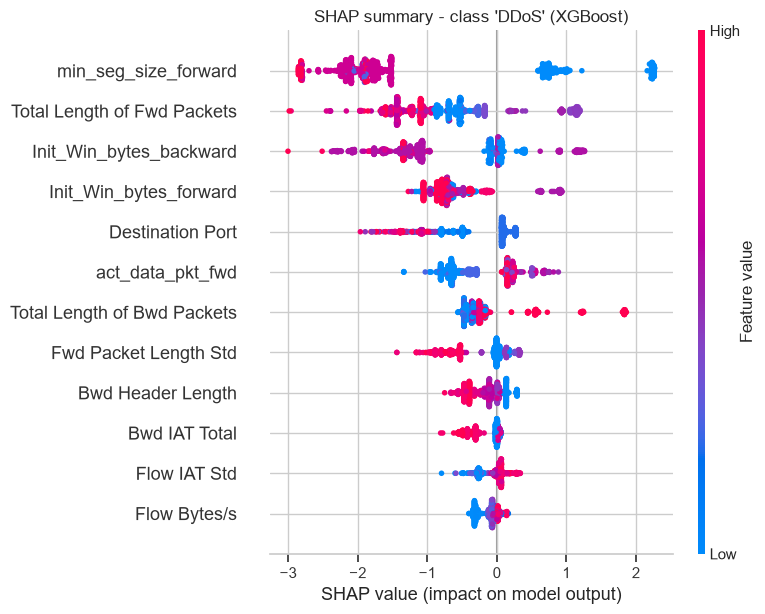

C:\Users\Surya\AppData\Local\Temp\ipykernel_15472\1534776920.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_x[k], X_shap, max_display=12, show=False); plt.title(f"SHAP summary - class '{cname}' (XGBoost)")


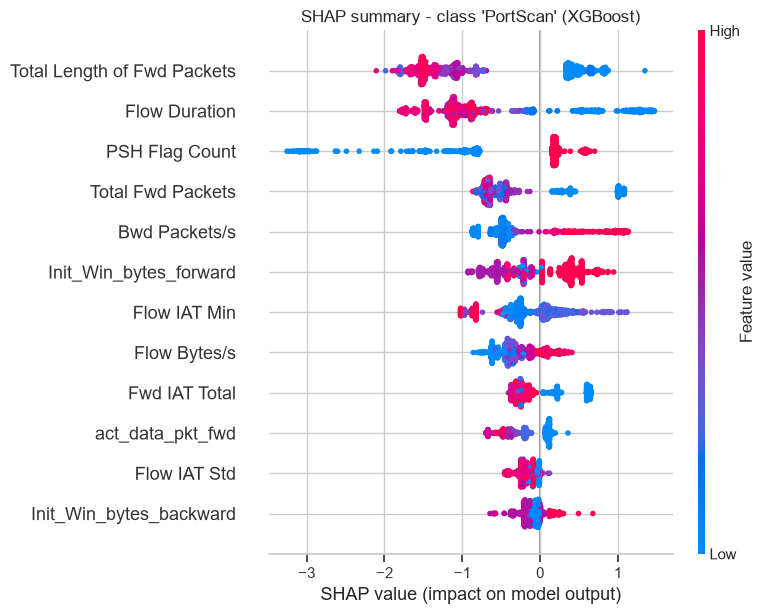

C:\Users\Surya\AppData\Local\Temp\ipykernel_15472\1534776920.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_x[k], X_shap, max_display=12, show=False); plt.title(f"SHAP summary - class '{cname}' (XGBoost)")


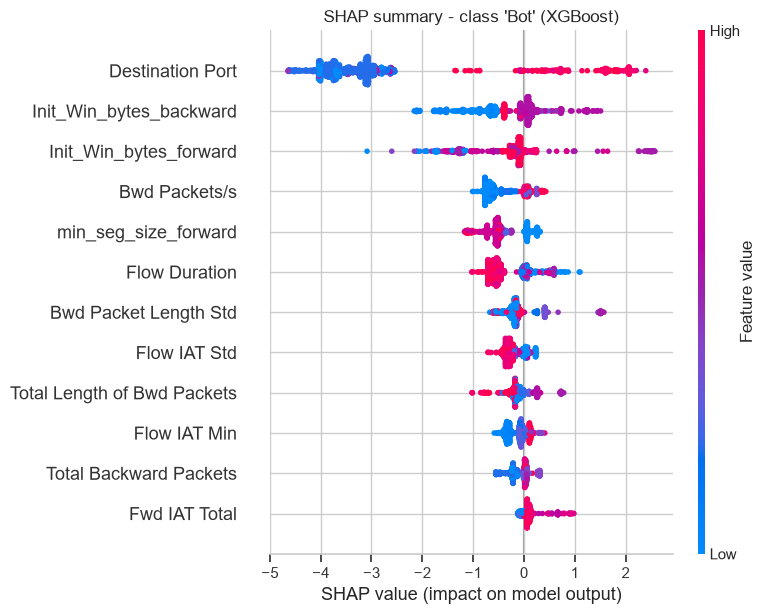

C:\Users\Surya\AppData\Local\Temp\ipykernel_15472\1534776920.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_x[k], X_shap, max_display=12, show=False); plt.title(f"SHAP summary - class '{cname}' (XGBoost)")


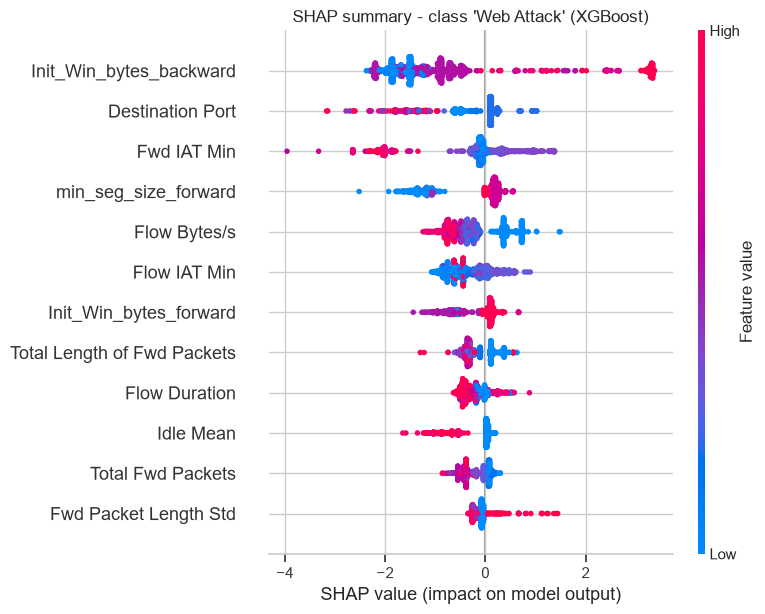

In [35]:
# ---- class-wise explanation ----
# (1) heatmap: for flows that truly belong to class k, which features push the model's class-k score? (XGBoost, row = feature, column normalised)
cw = pd.DataFrame({CLASS_NAMES[k]: np.abs(sv_x[k][y_shap == k]).mean(axis=0) if (y_shap == k).any() else np.zeros(len(selected_features))
                   for k in range(N_CLASSES)}, index=selected_features)
top_f = cw.div(cw.max(axis=0).replace(0, 1), axis=1).max(axis=1).sort_values(ascending=False).head(20).index      # features that matter most to at least one class
plt.figure(figsize=(12, 8))
sns.heatmap(cw.loc[top_f].div(cw.loc[top_f].max(axis=0).replace(0, 1), axis=1), cmap="viridis", annot=True, fmt=".2f", cbar_kws={"label": "relative mean |SHAP| (column-normalised)"})
plt.title("Class-wise SHAP (XGBoost): top features per attack category")
show("shap_classwise_heatmap"); cw.to_csv(OUT_DIR / "shap_classwise.csv")

# (2) beeswarm for a few classes: direction of each feature's effect on that class's score
focus = [c for c in ["DDoS", "PortScan", "Bot", "Web Attack"] if c in CLASS_NAMES][:4]
for cname in focus:
    k = CLASS_ID[cname]
    shap.summary_plot(sv_x[k], X_shap, max_display=12, show=False); plt.title(f"SHAP summary - class '{cname}' (XGBoost)")
    show(f"shap_summary_{cname.replace(' ', '_').lower()}")

Correct attack detection: row 0, true = DoS Hulk, predicted = DoS Hulk (p = 1.000)


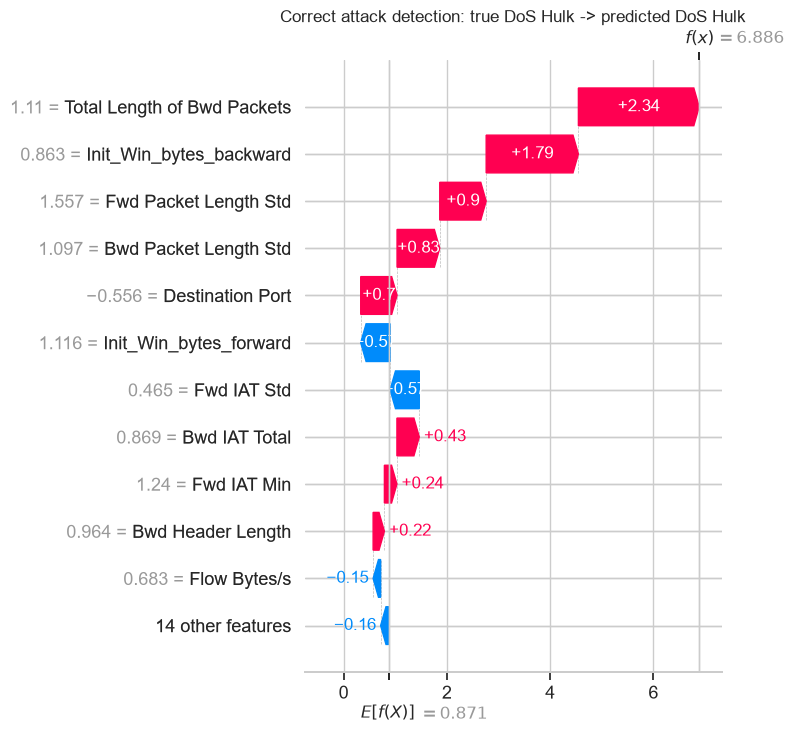

Misclassified flow: row 105, true = DoS Slowhttptest, predicted = DoS GoldenEye (p = 0.515)


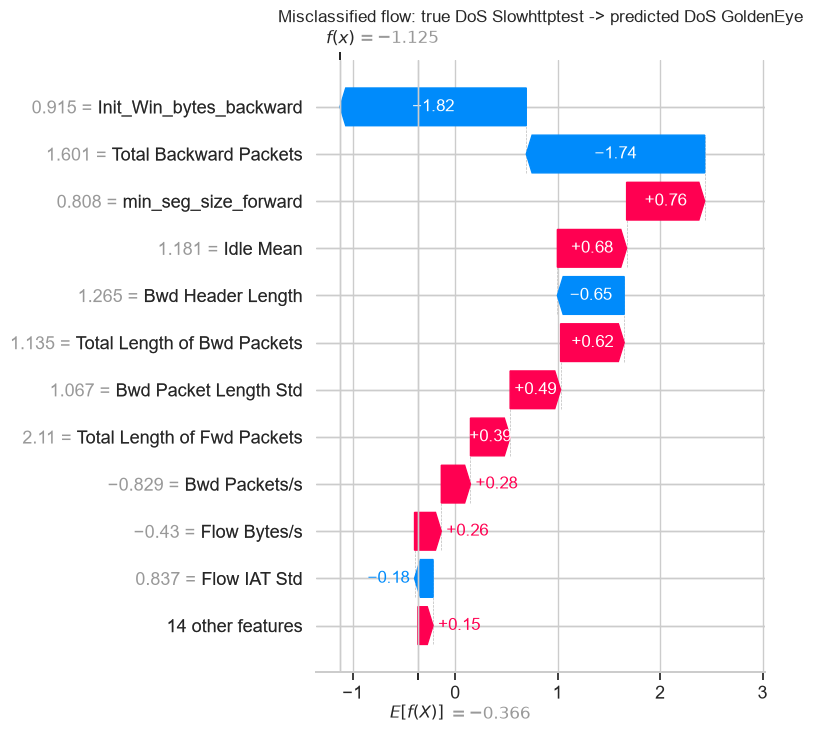

Correct benign flow: row 1, true = BENIGN, predicted = BENIGN (p = 1.000)


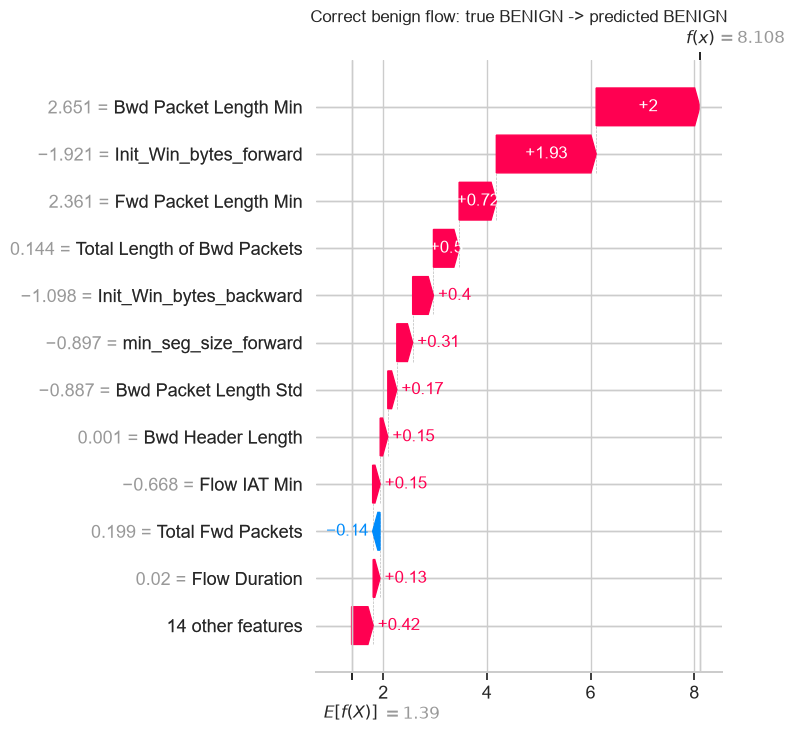

In [36]:
# ---- local explanations (XGBoost): one correctly detected attack, one misclassified flow (if any), one benign flow ----
xgb_m = registry[("GAN + Tuned", "XGBoost")]
P_shap = xgb_m.predict_proba(X_shap); pred_shap = P_shap.argmax(axis=1)
cases = {"Correct attack detection": np.flatnonzero((y_shap != 0) & (pred_shap == y_shap)),
         "Misclassified flow": np.flatnonzero(pred_shap != y_shap),
         "Correct benign flow": np.flatnonzero((y_shap == 0) & (pred_shap == 0))}
for j, (title, ids) in enumerate(cases.items()):
    if len(ids) == 0:
        print(f"{title}: no such case in the sample"); continue
    i = int(ids[0]); k = int(pred_shap[i])                                   # explain the class the model predicted
    print(f"{title}: row {i}, true = {CLASS_NAMES[y_shap[i]]}, predicted = {CLASS_NAMES[k]} (p = {P_shap[i, k]:.3f})")
    shap.plots.waterfall(shap.Explanation(values=sv_x[k][i], base_values=shap_base["XGBoost"][k], data=X_shap.iloc[i].to_numpy(), feature_names=selected_features), max_display=12, show=False)
    plt.title(f"{title}: true {CLASS_NAMES[y_shap[i]]} -> predicted {CLASS_NAMES[k]}"); show(f"shap_local_{j+1}")

## 23 · Multiclass evaluation — final ensemble (validation set)
Accuracy, macro and weighted precision / recall / F1, one-vs-rest ROC-AUC and PR-AUC (macro-averaged over classes), confusion matrix (counts and row-normalised) and the full classification report. **Accuracy and weighted scores are dominated by BENIGN and the big DoS classes; macro scores are the honest view of the rare classes.**

,Ensemble (Soft Voting)
accuracy,0.9988
balanced_accuracy,0.9815
macro_precision,0.9668
macro_recall,0.9815
macro_f1,0.9705
weighted_precision,0.9990
weighted_recall,0.9988
weighted_f1,0.9988
roc_auc,0.9999
pr_auc,0.9775


                  precision    recall  f1-score   support

          BENIGN     0.9999    0.9987    0.9993    314243
            DDoS     0.9982    0.9997    0.9989     19202
        DoS Hulk     0.9981    0.9996    0.9988     25927
   DoS GoldenEye     0.9903    0.9974    0.9939      1543
   DoS slowloris     0.9853    0.9950    0.9901       808
DoS Slowhttptest     0.9775    0.9962    0.9867       784
        PortScan     0.9897    0.9999    0.9948     13604
             Bot     0.6437    0.9897    0.7800       292
     FTP-Patator     0.9955    0.9989    0.9972       890
     SSH-Patator     1.0000    1.0000    1.0000       483
      Web Attack     0.9906    0.9844    0.9875       321
    Infiltration     1.0000    0.8000    0.8889         5
      Heartbleed     1.0000    1.0000    1.0000         2

        accuracy                         0.9988    378104
       macro avg     0.9668    0.9815    0.9705    378104
    weighted avg     0.9990    0.9988    0.9988    378104



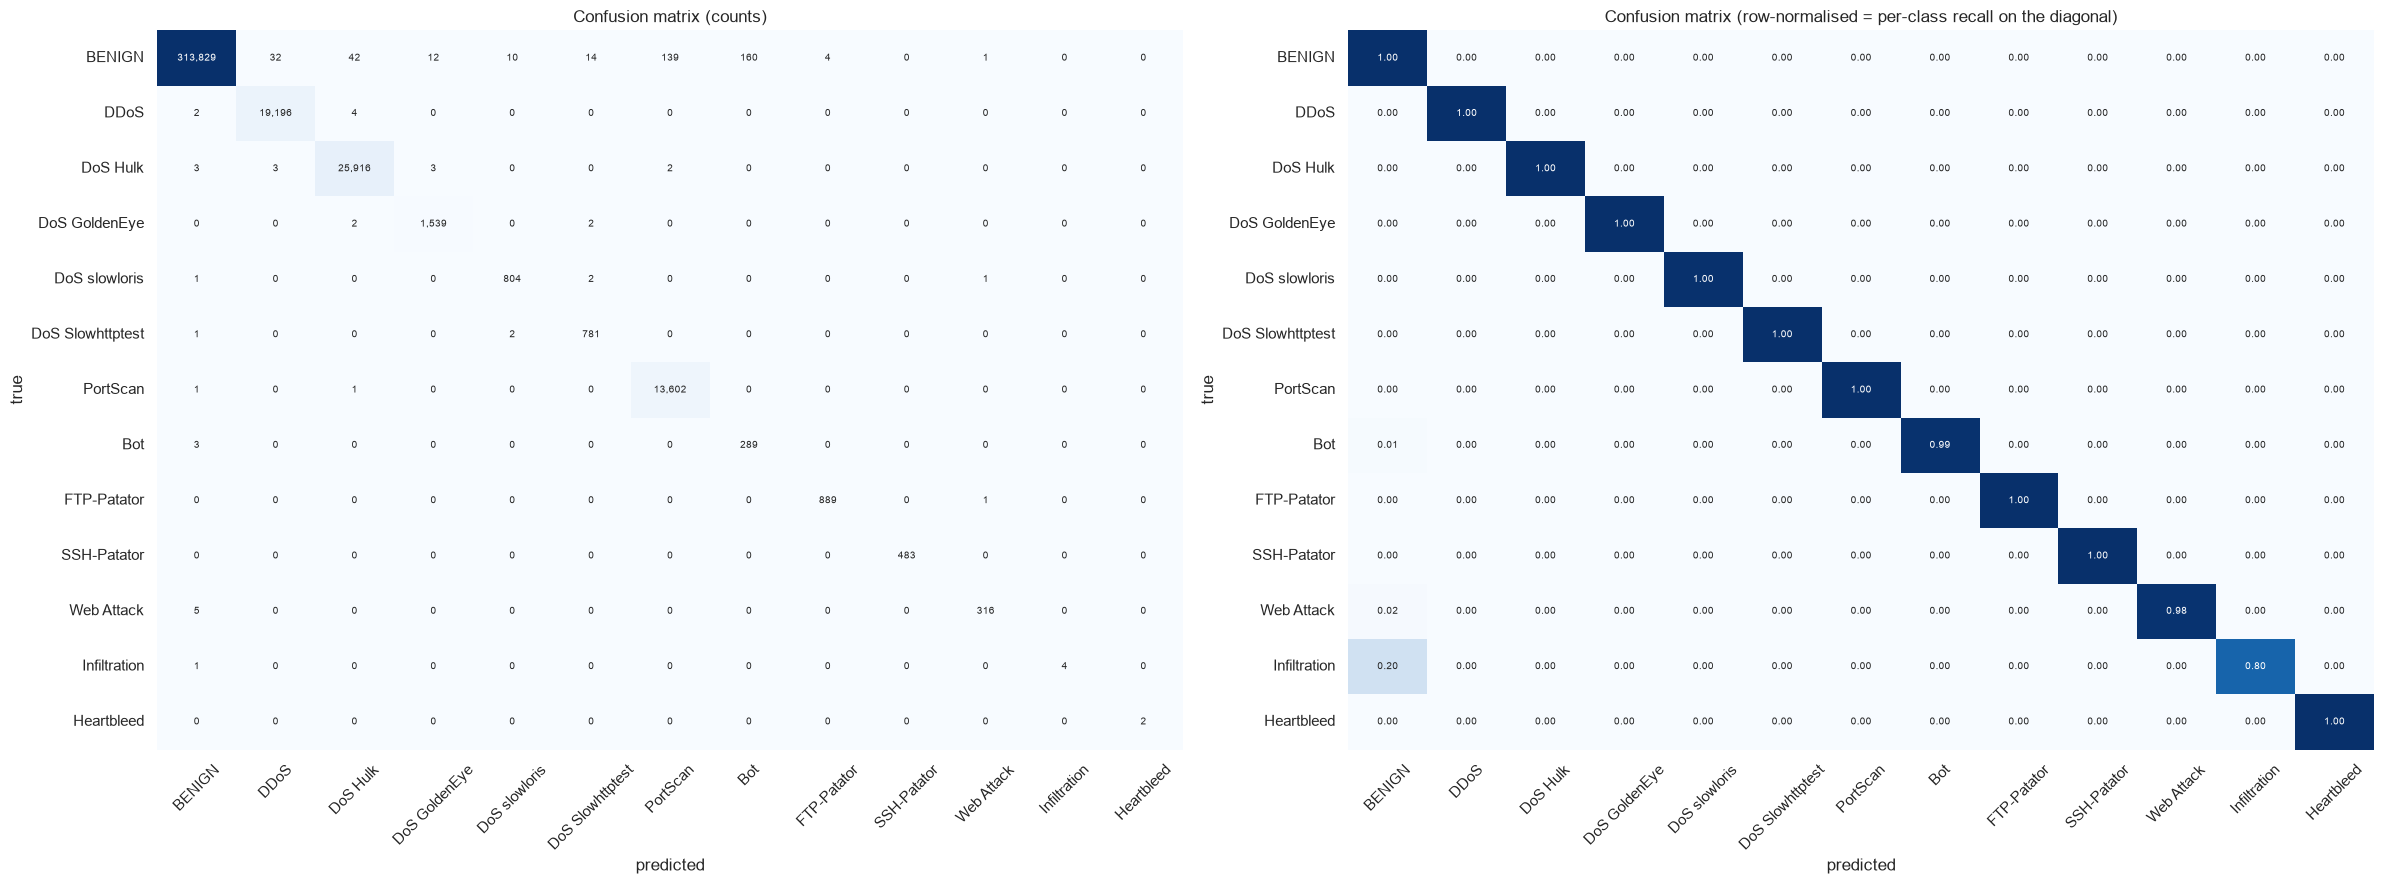

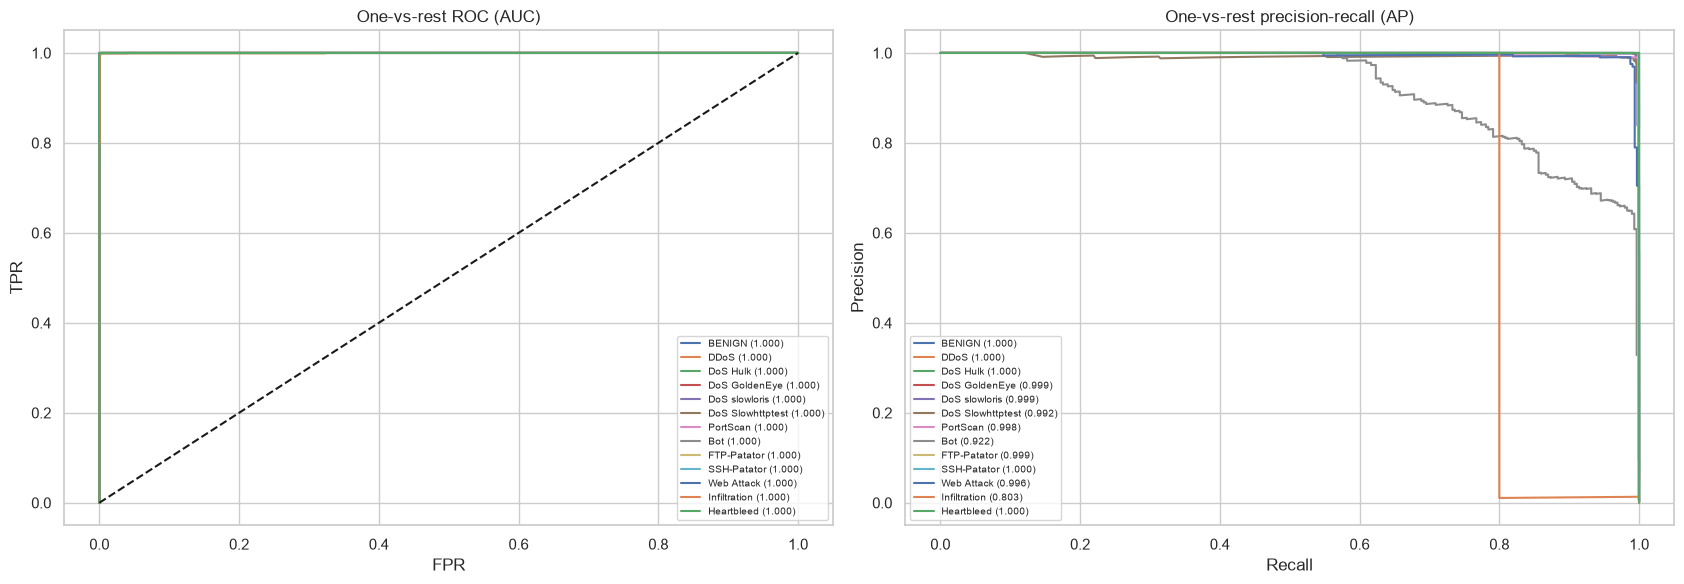

In [37]:
P_val = final_model.predict_proba(X_val_sel); y_val_pred = P_val.argmax(axis=1)
display(pd.Series(multiclass_metrics(y_val, P_val), name=FINAL_NAME).to_frame())
print(classification_report(y_val, y_val_pred, labels=LABELS, target_names=CLASS_NAMES, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(24, 9))
cm = confusion_matrix(y_val, y_val_pred, labels=LABELS)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0], cbar=False, annot_kws={"size": 7}); ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], cbar=False, annot_kws={"size": 7}); ax[1].set_title("Confusion matrix (row-normalised = per-class recall on the diagonal)")
for a in ax: a.set_xlabel("predicted"); a.set_ylabel("true"); a.tick_params(axis="x", rotation=45)
show("eval_confusion_validation")

yb = label_binarize(y_val, classes=LABELS); fig, ax = plt.subplots(1, 2, figsize=(17, 6))
for k in LABELS:
    if 0 < yb[:, k].sum() < len(y_val):
        fpr, tpr, _ = roc_curve(yb[:, k], P_val[:, k]); ax[0].plot(fpr, tpr, label=f"{CLASS_NAMES[k]} ({roc_auc_score(yb[:, k], P_val[:, k]):.3f})")
        p_, r_, _ = precision_recall_curve(yb[:, k], P_val[:, k]); ax[1].plot(r_, p_, label=f"{CLASS_NAMES[k]} ({average_precision_score(yb[:, k], P_val[:, k]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="One-vs-rest ROC (AUC)", xlabel="FPR", ylabel="TPR"); ax[0].legend(fontsize=7)
ax[1].set(title="One-vs-rest precision-recall (AP)", xlabel="Recall", ylabel="Precision"); ax[1].legend(fontsize=7)
show("eval_roc_pr_validation")

## 24 · Per-class evaluation
Precision / recall / F1 / support for **each of the 14 workflow classes** (classes that do not exist in the dataset are shown as "not present"), followed by a per-class comparison of the four training scenarios. Oversampling should matter most on the rare classes here.

Final model: Ensemble (Soft Voting)  (validation set)


,precision,recall,f1,support,note
BENIGN,0.9999,0.9987,0.9993,314243,
DDoS,0.9982,0.9997,0.9989,19202,
DoS Hulk,0.9981,0.9996,0.9988,25927,
DoS GoldenEye,0.9903,0.9974,0.9939,1543,
DoS slowloris,0.9853,0.9950,0.9901,808,
DoS Slowhttptest,0.9775,0.9962,0.9867,784,
PortScan,0.9897,0.9999,0.9948,13604,
Bot,0.6437,0.9897,0.7800,292,
FTP-Patator,0.9955,0.9989,0.9972,890,
SSH-Patator,1.0000,1.0000,1.0000,483,


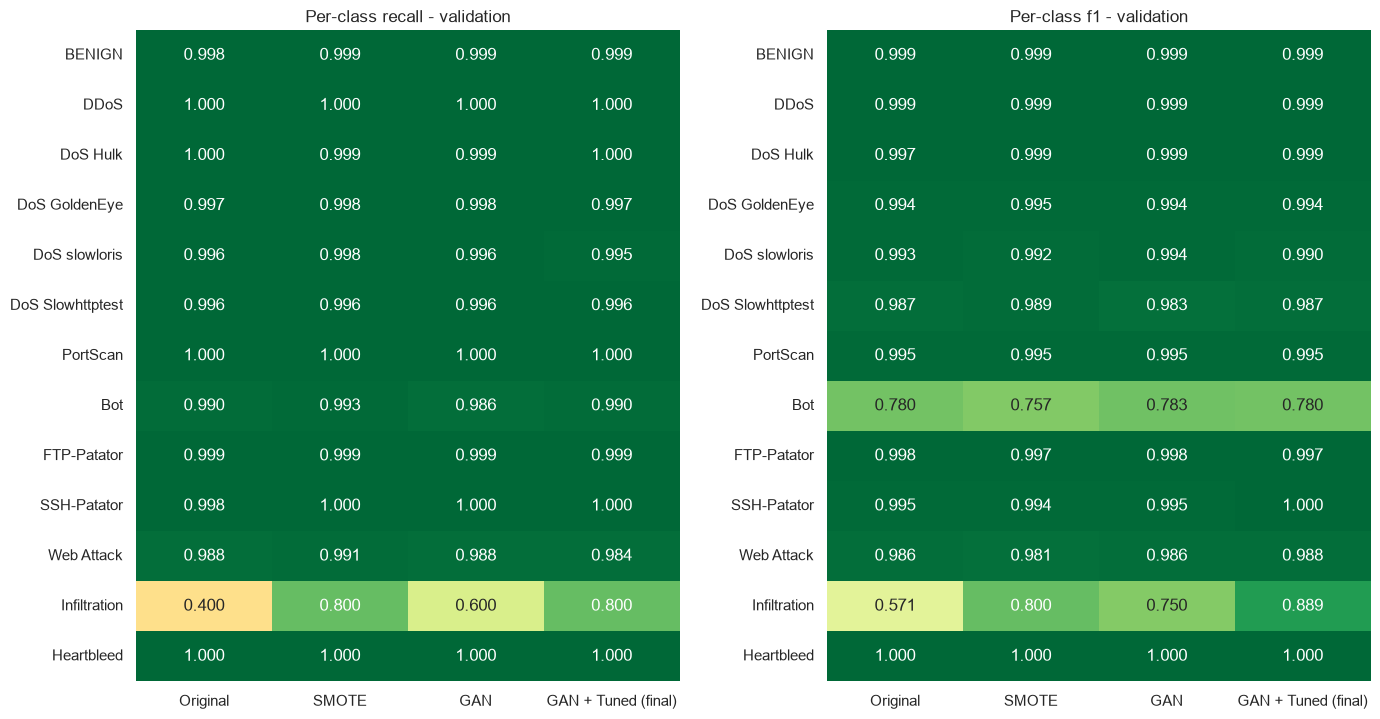

In [38]:
def per_class_table(y_true, pred):
    p, r, f, s = precision_recall_fscore_support(y_true, pred, labels=LABELS, zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=CLASS_NAMES)

def per_class_by_model(models, X_, y_, metric):
    return pd.DataFrame({lbl: per_class_table(y_, m.predict(X_))[metric] for lbl, m in models.items()})

def full_class_table(tbl):
    out = tbl.reindex(CLASS_ORDER); out["support"] = out["support"].fillna(0).astype(int)
    out["note"] = np.where(out.index.isin(CLASS_NAMES), "", "not present in dataset"); return out

print(f"Final model: {FINAL_NAME}  (validation set)")
display(full_class_table(per_class_table(y_val, y_val_pred)))

scen_models = {"Original": registry[("Original", "Ensemble (Soft Voting)")], "SMOTE": registry[("SMOTE", "Ensemble (Soft Voting)")],
               "GAN": registry[("GAN", "Ensemble (Soft Voting)")], "GAN + Tuned (final)": final_model}

def scenario_heatmaps(X_, y_, split):
    fig, ax = plt.subplots(1, 2, figsize=(14, max(4, .45 * N_CLASSES + 1.5)))
    for a, mtr in zip(ax, ["recall", "f1"]):
        sns.heatmap(per_class_by_model(scen_models, X_, y_, mtr), annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=1, ax=a, cbar=False); a.set_title(f"Per-class {mtr} - {split}")
    return fig

scenario_heatmaps(X_val_sel, y_val, "validation"); show("per_class_scenarios_validation")

## 25 · Original vs SMOTE vs GAN (validation set)

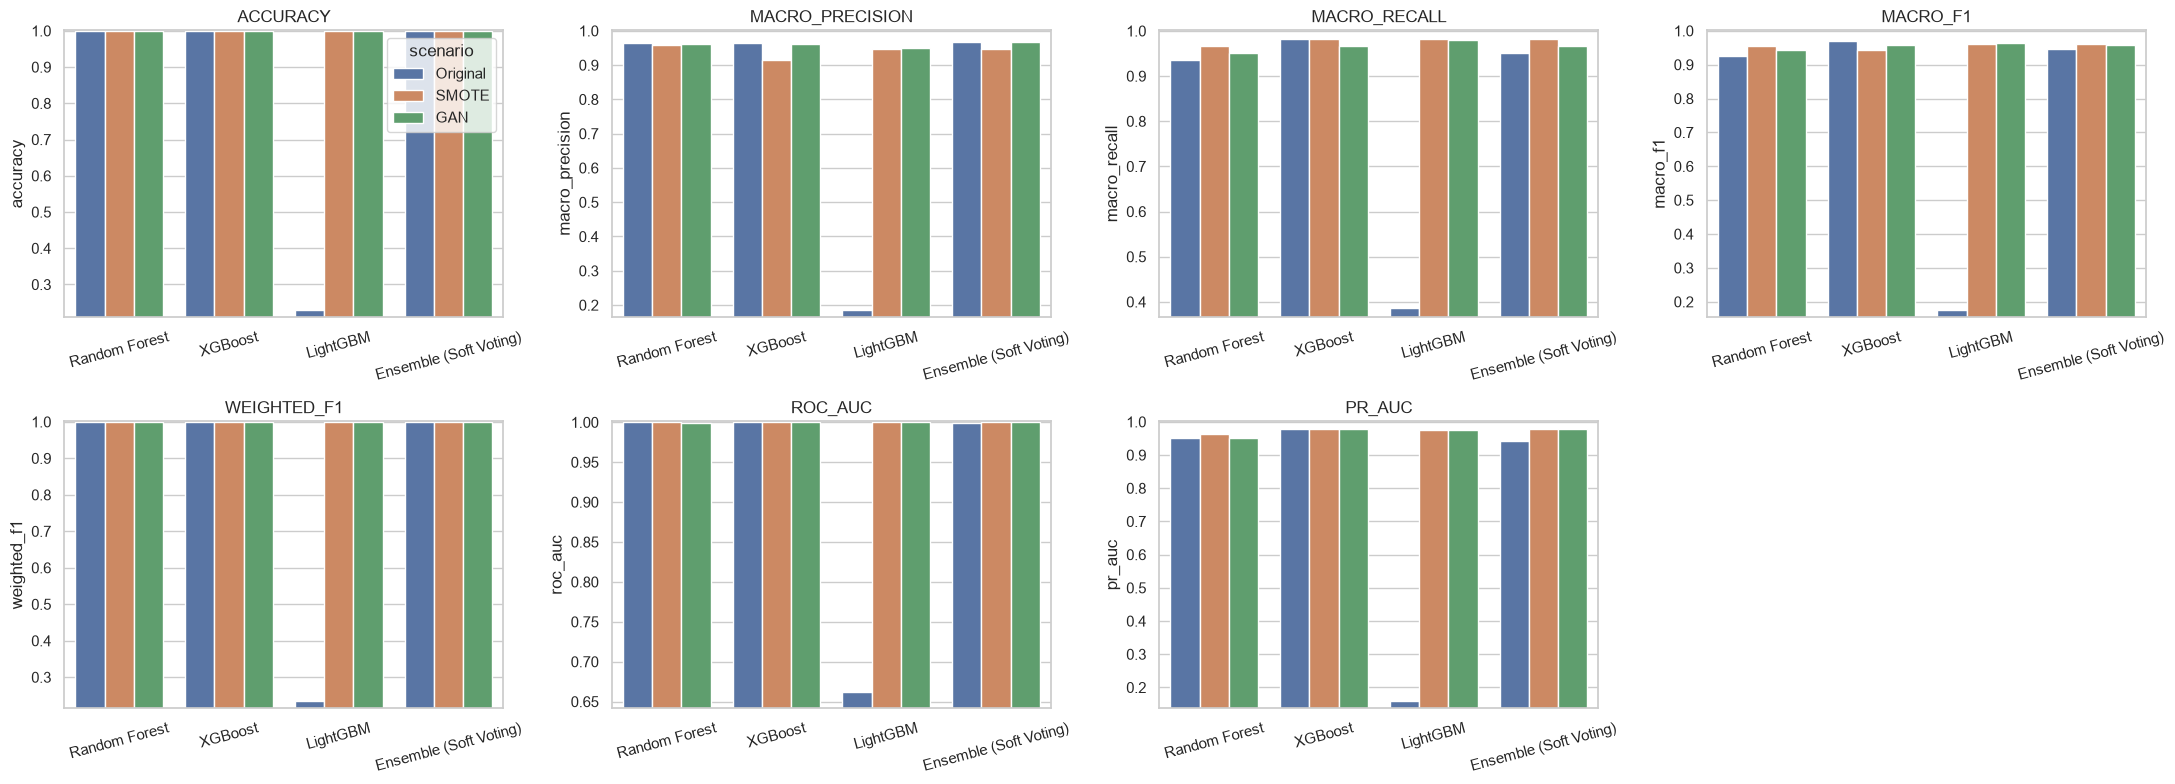

accuracy                 macro_precision           \
scenario                    GAN Original  SMOTE             GAN Original   
model                                                                      
Ensemble (Soft Voting)   0.9988   0.9986 0.9987          0.9660   0.9662   
LightGBM                 0.9987   0.2300 0.9987          0.9499   0.1849   
Random Forest            0.9986   0.9986 0.9984          0.9619   0.9645   
XGBoost                  0.9987   0.9987 0.9986          0.9622   0.9648   

                              macro_recall                 macro_f1           \
scenario                SMOTE          GAN Original  SMOTE      GAN Original   
model                                                                          
Ensemble (Soft Voting) 0.9471       0.9662   0.9508 0.9825   0.9595   0.9458   
LightGBM               0.9457       0.9804   0.3862 0.9819   0.9625   0.1748   
Random Forest          0.9582       0.9501   0.9347 0.9660   0.9436   0.9268   
XGBoost                0.9157       0.9671   0.9823 0.9827   0.9574   0.9697   

                              weighted_f1                 roc_auc           \
scenario                SMOTE         GAN Original  SMOTE     GAN Original   
model                                                                        
Ensemble (Soft Voting) 0.9612      0.9988   0.9986 0.9988  1.0000   0.9989   
LightGBM               0.9604      0.9988   0.2353 0.9987  0.9999   0.6619   
Random Forest          0.9547      0.9986   0.9986 0.9985  0.9997   0.9998   
XGBoost                0.9421      0.9988   0.9988 0.9986  0.9999   0.9999   

                              pr_auc                  
scenario                SMOTE    GAN Original  SMOTE  
model                                                 
Ensemble (Soft Voting) 1.0000 0.9774   0.9433 0.9768  
LightGBM               0.9999 0.9745   0.1578 0.9751  
Random Forest          0.9998 0.9527   0.9498 0.9635  
XGBoost                0.9999 0.9783   0.9779 0.9789

In [39]:
res = pd.DataFrame(results); res_val = res[res["split"] == "validation"]
compare = res_val[res_val["scenario"].isin(["Original", "SMOTE", "GAN"]) & res_val["model"].isin(TREE_NAMES + ["Ensemble (Soft Voting)"])]
metrics7 = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "roc_auc", "pr_auc"]
fig, axes = plt.subplots(2, 4, figsize=(22, 8)); axes = axes.ravel()
for a, mtr in zip(axes, metrics7):
    sns.barplot(data=compare, x="model", y=mtr, hue="scenario", ax=a)
    lo = compare[mtr].min(); a.set_ylim(max(0, lo - 0.02), 1.001); a.set_title(mtr.upper()); a.set_xlabel(""); a.tick_params(axis="x", rotation=15)
    if a is not axes[0]: a.get_legend().remove()
axes[-1].axis("off")
show("compare_original_smote_gan")
display(compare.pivot_table(index="model", columns="scenario", values=metrics7)[metrics7])

## 26 · Final evaluation on the CICIDS2017 test set
First time the test set is used: every registered model is scored once, no further tuning.

,scenario,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,roc_auc,pr_auc,mcc,errors
0,GAN + Tuned,Ensemble (Soft Voting),0.9988,0.9677,0.9821,0.9715,0.9990,0.9988,0.9989,1.0000,0.9867,0.9961,444
1,GAN + Tuned,Ensemble (Hard Voting),0.9988,0.9671,0.9817,0.9711,0.9989,0.9988,0.9988,0.9911,0.9542,0.9960,452
2,Original,Ensemble (Soft Voting),0.9986,0.9666,0.9812,0.9706,0.9988,0.9986,0.9987,0.9993,0.9727,0.9954,524
3,GAN,Ensemble (Soft Voting),0.9988,0.9660,0.9815,0.9704,0.9989,0.9988,0.9988,1.0000,0.9780,0.9959,465
4,GAN + Tuned,LightGBM,0.9988,0.9669,0.9808,0.9704,0.9989,0.9988,0.9988,1.0000,0.9824,0.9959,465
5,Original,Random Forest,0.9986,0.9648,0.9811,0.9699,0.9987,0.9986,0.9986,0.9997,0.9706,0.9953,539
6,GAN + Tuned,Random Forest,0.9986,0.9643,0.9808,0.9694,0.9987,0.9986,0.9986,0.9998,0.9759,0.9954,531
7,GAN,Random Forest,0.9985,0.9615,0.9808,0.9680,0.9987,0.9985,0.9986,0.9997,0.9705,0.9952,553
8,SMOTE,Random Forest,0.9985,0.9584,0.9820,0.9659,0.9987,0.9985,0.9985,0.9997,0.9646,0.9949,581
9,Original,XGBoost,0.9987,0.9379,0.9816,0.9562,0.9989,0.9987,0.9988,1.0000,0.9851,0.9957,488


FINAL MODEL = GAN + Tuned / Ensemble (Soft Voting)  (selected on validation)
                  precision    recall  f1-score   support

          BENIGN     1.0000    0.9987    0.9993    314243
            DDoS     0.9982    0.9999    0.9991     19202
        DoS Hulk     0.9981    0.9998    0.9989     25927
   DoS GoldenEye     0.9948    1.0000    0.9974      1543
   DoS slowloris     0.9817    0.9950    0.9883       808
DoS Slowhttptest     0.9724    0.9872    0.9797       784
        PortScan     0.9890    0.9996    0.9943     13604
             Bot     0.6636    0.9932    0.7956       292
     FTP-Patator     1.0000    1.0000    1.0000       890
     SSH-Patator     0.9979    1.0000    0.9990       483
      Web Attack     0.9846    0.9938    0.9891       321
    Infiltration     1.0000    0.8000    0.8889         5
      Heartbleed     1.0000    1.0000    1.0000         2

        accuracy                         0.9988    378104
       macro avg     0.9677    0.9821    0.9715    

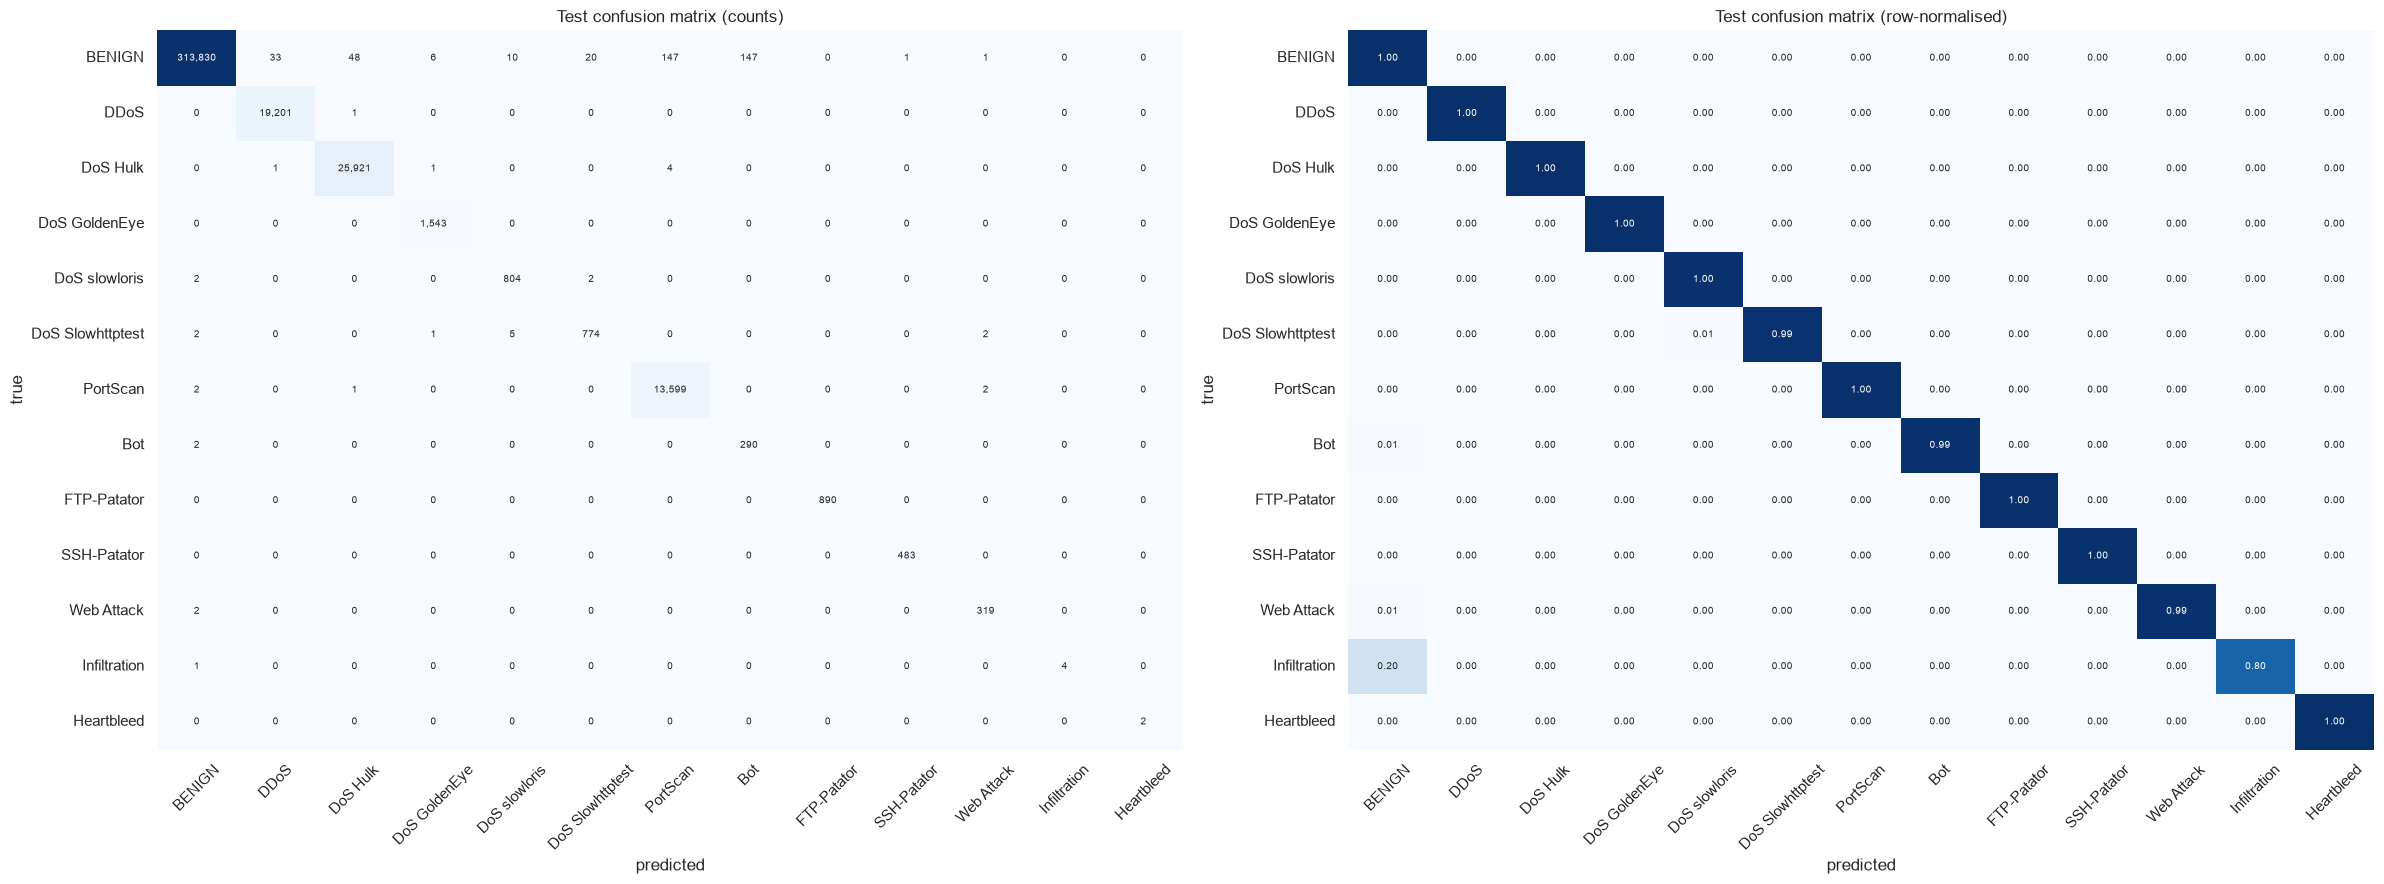

Per-class results - TEST (final model):


,precision,recall,f1,support,note
BENIGN,1.0000,0.9987,0.9993,314243,
DDoS,0.9982,0.9999,0.9991,19202,
DoS Hulk,0.9981,0.9998,0.9989,25927,
DoS GoldenEye,0.9948,1.0000,0.9974,1543,
DoS slowloris,0.9817,0.9950,0.9883,808,
DoS Slowhttptest,0.9724,0.9872,0.9797,784,
PortScan,0.9890,0.9996,0.9943,13604,
Bot,0.6636,0.9932,0.7956,292,
FTP-Patator,1.0000,1.0000,1.0000,890,
SSH-Patator,0.9979,1.0000,0.9990,483,


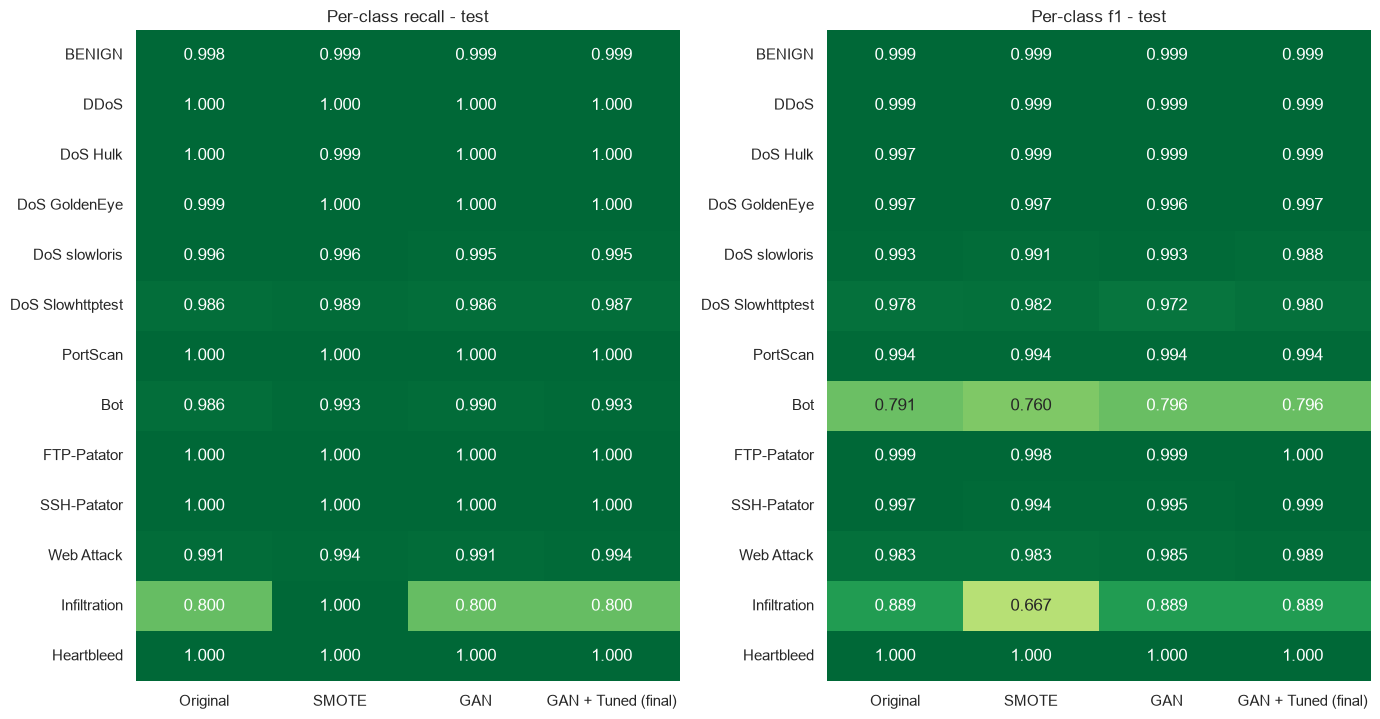

Note: Heartbleed / Infiltration have only a handful of test flows - one error moves their recall by 15-50 points.


In [40]:
test_rows = [evaluate(m, X_test_sel, y_test, sc, nm, "test") for (sc, nm), m in registry.items()]
results_test = pd.DataFrame(test_rows)
cols = ["scenario", "model"] + METRIC_COLS + ["errors"]
display(results_test[cols].sort_values(["macro_f1", "mcc"], ascending=False).reset_index(drop=True))

P_test = final_model.predict_proba(X_test_sel); y_test_pred = P_test.argmax(axis=1)
print(f"FINAL MODEL = GAN + Tuned / {FINAL_NAME}  (selected on validation)")
print(classification_report(y_test, y_test_pred, labels=LABELS, target_names=CLASS_NAMES, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(24, 9)); cm = confusion_matrix(y_test, y_test_pred, labels=LABELS)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0], cbar=False, annot_kws={"size": 7}); ax[0].set_title("Test confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], cbar=False, annot_kws={"size": 7}); ax[1].set_title("Test confusion matrix (row-normalised)")
for a in ax: a.set_xlabel("predicted"); a.set_ylabel("true"); a.tick_params(axis="x", rotation=45)
show("eval_confusion_test")

det_test = full_class_table(per_class_table(y_test, y_test_pred)); print("Per-class results - TEST (final model):"); display(det_test)
scenario_heatmaps(X_test_sel, y_test, "test"); show("per_class_scenarios_test")
print("Note: Heartbleed / Infiltration have only a handful of test flows - one error moves their recall by 15-50 points.")

## 27 · Model comparison (test set)

,label,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,roc_auc,pr_auc,mcc,errors
0,Logistic Regression,0.9861,0.6977,0.9243,0.7746,0.9891,0.9861,0.9872,0.9922,0.7857,0.9559,5262
1,Decision Tree,0.9975,0.8257,0.9780,0.8716,0.9979,0.9975,0.9976,0.9889,0.8192,0.9916,962
2,Random Forest,0.9986,0.9648,0.9811,0.9699,0.9987,0.9986,0.9986,0.9997,0.9706,0.9953,539
3,XGBoost,0.9987,0.9379,0.9816,0.9562,0.9989,0.9987,0.9988,1.0000,0.9851,0.9957,488
4,LightGBM,0.2302,0.1856,0.3897,0.1757,0.8427,0.2302,0.2357,0.6636,0.1584,0.2658,291051
5,Ensemble (Soft Voting),0.9986,0.9666,0.9812,0.9706,0.9988,0.9986,0.9987,0.9993,0.9727,0.9954,524
6,GAN+Tuned Ens. (Soft Voting),0.9988,0.9677,0.9821,0.9715,0.9990,0.9988,0.9989,1.0000,0.9867,0.9961,444


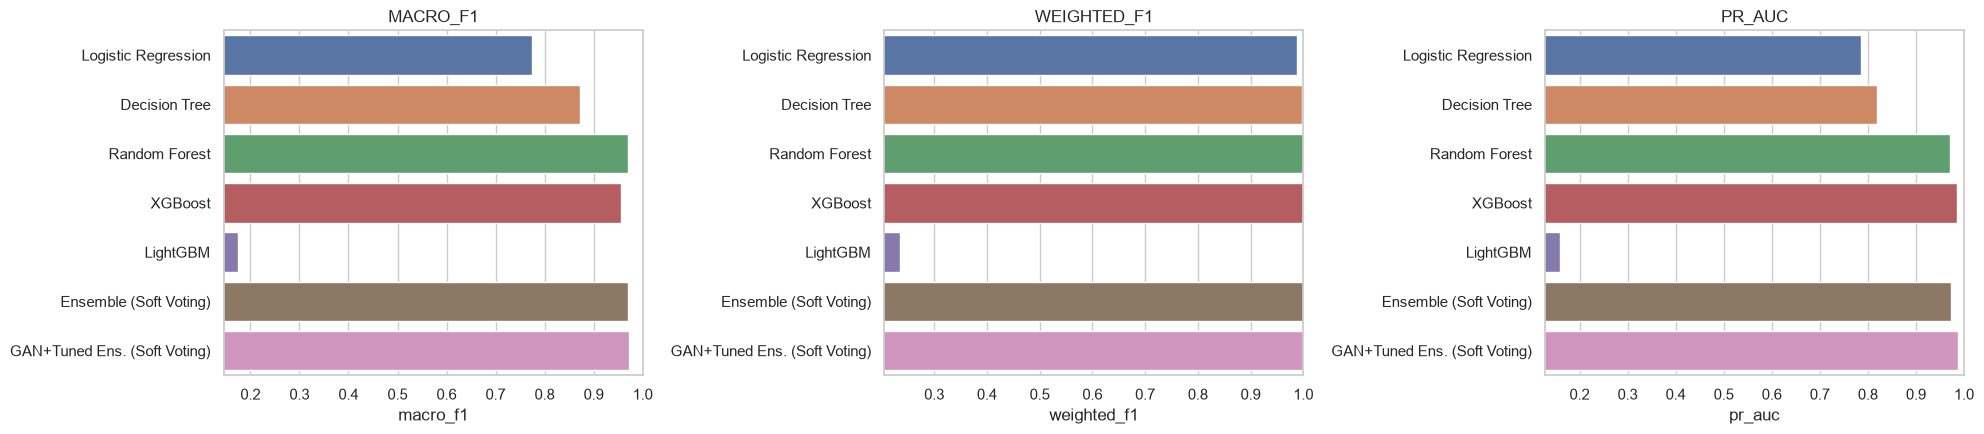

In [41]:
rows = [("Original", "Logistic Regression"), ("Original", "Decision Tree"), ("Original", "Random Forest"), ("Original", "XGBoost"),
        ("Original", "LightGBM"), ("Original", "Ensemble (Soft Voting)"), ("GAN + Tuned", FINAL_NAME)]
cmp_ = results_test.set_index(["scenario", "model"]).loc[rows].reset_index()
cmp_["label"] = np.where(cmp_["scenario"] == "Original", cmp_["model"], "GAN+Tuned " + cmp_["model"].str.replace("Ensemble ", "Ens. "))
display(cmp_[["label"] + METRIC_COLS + ["errors"]])
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
for a, mtr in zip(ax, ["macro_f1", "weighted_f1", "pr_auc"]):
    sns.barplot(data=cmp_, y="label", x=mtr, ax=a, hue="label", legend=False); a.set_xlim(max(0, cmp_[mtr].min() - 0.03), 1.0); a.set_title(mtr.upper()); a.set_ylabel("")
show("model_comparison_test")

## 28 · Save final model, scaler, encoder and selected features
`ids_utils.py` (written in cell 03) must sit next to the saved files when loading them elsewhere.

In [42]:
joblib.dump(final_model, MODEL_DIR / "final_model.joblib")
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.joblib")       # signed-log + StandardScaler (fit on train only)
joblib.dump(label_encoder, MODEL_DIR / "label_encoder.joblib")     # class id <-> attack-category name
json.dump(selected_features, open(MODEL_DIR / "selected_features.json", "w"), indent=2)
json.dump(list(X_train.columns), open(MODEL_DIR / "feature_columns.json", "w"), indent=2)   # raw input columns expected
json.dump({"final_model": FINAL_NAME, "scenario": "GAN + Tuned", "gan": "conditional WGAN-GP", "classes": CLASS_NAMES, "best_params": best_params,
           "oversample_target": OVERSAMPLE_TARGET, "class_cap": CLASS_CAP, "train_rows_real": int(len(X_train)),
           "synthetic_rows": int(len(X_syn)), "random_state": RANDOM_STATE}, open(MODEL_DIR / "metadata.json", "w"), indent=2, default=str)

# reload sanity check: raw rows -> saved pipeline must reproduce the in-notebook probabilities
det = IDSDetector(MODEL_DIR)
raw_chunk = X_test.iloc[:2000]
assert np.allclose(det.predict_proba(raw_chunk), final_model.predict_proba(X_test_sel.iloc[:2000]), atol=1e-4), "reload mismatch"
print("saved:", sorted(p.name for p in MODEL_DIR.iterdir())); print("reload check passed ->", det.predict(raw_chunk.iloc[:5]))

saved: ['feature_columns.json', 'final_model.joblib', 'label_encoder.joblib', 'metadata.json', 'preprocessor.joblib', 'selected_features.json']
reload check passed -> ['BENIGN' 'BENIGN' 'BENIGN' 'BENIGN' 'BENIGN']


## 29 · Final results & conclusion

In [43]:
results_all = pd.concat([pd.DataFrame(results), results_test.assign(fit_time_s=np.nan)], ignore_index=True)
results_all.to_csv(OUT_DIR / "all_results.csv", index=False); det_test.to_csv(OUT_DIR / "per_class_results_test.csv")

t = results_test.set_index(["scenario", "model"])
ens = {sc: t.loc[(sc, "Ensemble (Soft Voting)")] for sc in ["Original", "SMOTE", "GAN", "GAN + Tuned"]}
print("TEST-SET SOFT-VOTING ENSEMBLE, by training scenario")
print(pd.DataFrame(ens).T[["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "roc_auc", "pr_auc", "mcc", "errors"]].to_string())
d = lambda a, b, m: ens[a][m] - ens[b][m]
print(f"\nGAN vs Original : dMacroF1 = {d('GAN','Original','macro_f1'):+.4f}, dMacroRecall = {d('GAN','Original','macro_recall'):+.4f}, dAcc = {d('GAN','Original','accuracy'):+.4f}")
print(f"GAN vs SMOTE    : dMacroF1 = {d('GAN','SMOTE','macro_f1'):+.4f}, dMacroRecall = {d('GAN','SMOTE','macro_recall'):+.4f}, dAcc = {d('GAN','SMOTE','accuracy'):+.4f}")
best = results_test.sort_values(["macro_f1", "mcc"], ascending=False).iloc[0]
print(f"\nBest test model by macro-F1: {best['scenario']} / {best['model']}  (macro-F1={best['macro_f1']:.4f}, acc={best['accuracy']:.4f}, MCC={best['mcc']:.4f})")
weak = det_test.dropna(subset=["f1"]).sort_values("f1").head(3)
print("Hardest classes (final model, test F1):", ", ".join(f"{i} ({r.f1:.2f}, n={int(r.support)})" for i, r in weak.iterrows()))
print("Top SHAP features (ensemble):", ", ".join(mean_abs.index[:8]))

TEST-SET SOFT-VOTING ENSEMBLE, by training scenario
            accuracy macro_precision macro_recall macro_f1 weighted_f1 roc_auc pr_auc    mcc errors
Original      0.9986          0.9666       0.9812   0.9706      0.9987  0.9993 0.9727 0.9954    524
SMOTE         0.9987          0.9239       0.9976   0.9510      0.9987  1.0000 0.9916 0.9957    497
GAN           0.9988          0.9660       0.9815   0.9704      0.9988  1.0000 0.9780 0.9959    465
GAN + Tuned   0.9988          0.9677       0.9821   0.9715      0.9989  1.0000 0.9867 0.9961    444

GAN vs Original : dMacroF1 = -0.0001, dMacroRecall = +0.0003, dAcc = +0.0002
GAN vs SMOTE    : dMacroF1 = +0.0195, dMacroRecall = -0.0162, dAcc = +0.0001

Best test model by macro-F1: GAN + Tuned / Ensemble (Soft Voting)  (macro-F1=0.9715, acc=0.9988, MCC=0.9961)
Hardest classes (final model, test F1): Bot (0.80, n=292), Infiltration (0.89, n=5), DoS Slowhttptest (0.98, n=784)
Top SHAP features (ensemble): Destination Port, min_seg_size_forwar

### How to read / write up these results
1. **Use macro metrics for the claim.** Accuracy and weighted-F1 on CICIDS2017 are ≈ 0.99+ for almost any tree model because BENIGN and the big DoS classes dominate. Macro-F1 / macro-recall (and the per-class tables in steps 24 and 26) are where Original, SMOTE and GAN can actually differ.
2. **The rarest classes are statistically thin.** Heartbleed (~11 flows in total) and Infiltration (~36) leave only a couple of validation/test flows each, so their recall is 0 / 50 / 100 % by chance. Do not claim a GAN gain from a single flow: repeat with several seeds (or stratified k-fold) and test significance (paired bootstrap / McNemar) before saying one oversampler beats another.
3. **Check what the GAN learned.** For classes with only a few real rows the cWGAN-GP mostly reproduces them (see the nearest-neighbour columns in step 17e). Classes with thousands of rows (Bot, Web Attack, SSH/FTP-Patator, DoS variants) are where synthetic data is meaningful.
4. **Same real data everywhere.** All scenarios share the identical per-class-capped training split; report `CLASS_CAP`, `OVERSAMPLE_TARGET` and the GAN validation table in the paper. Validation/test keep the natural distribution.
5. **Grouping choices matter.** Web Attack merges Brute Force / XSS / SQL Injection (as in the workflow); XSS and Brute Force are nearly indistinguishable on flow features, so confusions inside this group are expected. "Other Attack Classes" is empty for the standard CSVs.
6. **Explainability.** SHAP (steps 22) is computed in the scaled/log feature space on a class-stratified test sample: global, class-wise and local views. Confirm on another dataset (UNSW-NB15 / CIC-IDS2018) before generalising; CICIDS2017 has known labelling artefacts.